# 🧠 Sesión 09-A: Transfer Learning — Feature Extraction

**Curso:** IS056B — Ingeniería del Conocimiento
**Docente:** Msc. Jaime Antonio Huaytalla Pariona
**Universidad:** UNCP — Facultad de Ingeniería de Sistemas
**Semestre:** 2026-II | **Unidad II:** Transferencia de Aprendizaje, Series de Tiempo y MLOps

---

### 🎯 Objetivos de este notebook
1. **Comprender** qué es Transfer Learning y por qué supera al entrenamiento desde cero
2. **Implementar** Feature Extraction con backbones pre-entrenados de Keras
3. **Practicar** con 3 ejemplos progresivos usando datasets públicos
4. **Visualizar** features transferidos y comparar rendimiento de diferentes backbones

### 📚 Estructura
| Ejemplo | Nivel | Dataset | Modelo Base | Enfoque |
|---------|-------|---------|-------------|---------|
| 1 | 🟢 Básico | Chest X-Ray Pneumonia | MobileNetV2 | Primer Feature Extraction |
| 2 | 🟡 Intermedio | Colorectal Histology (8 clases) | EfficientNetB0 | EDA + Augmentation + Métricas |
| 3 | 🔴 Avanzado | Colorectal Histology (del Ejemplo 2) | Comparación 4 backbones | Benchmark + t-SNE |

## ⚙️ Configuración del Entorno

Verificamos GPU disponible e instalamos dependencias.

In [1]:
# Verificar GPU
import subprocess
gpu_info = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total',
                          '--format=csv,noheader'], capture_output=True, text=True)
print("🖥️ GPU detectada:", gpu_info.stdout.strip() or "⚠️ No hay GPU — activa en Runtime > Change runtime type > T4 GPU")

🖥️ GPU detectada: Tesla T4, 15360 MiB


In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Configuración global
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

print(f"✅ TensorFlow {tf.__version__}")
print(f"✅ GPU disponible: {tf.config.list_physical_devices('GPU')}")

✅ TensorFlow 2.21.0
✅ GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
# 📖 Fundamentos de Transfer Learning

## ¿Qué es Transfer Learning?

> **Transferir conocimiento** de una tarea donde hay abundancia de datos (ej. ImageNet: 14M imágenes, 1000 clases) a una tarea donde tenemos pocos datos (nuestro problema específico).

### Analogía humana
Un músico que sabe tocar piano aprende guitarra más rápido que alguien que parte de cero. ¿Por qué? Porque ya tiene:
- Coordinación motora fina → **Features de bajo nivel** (bordes, texturas)
- Teoría musical → **Features de nivel medio** (patrones, formas)
- Sensibilidad rítmica → **Features de alto nivel** (estructuras complejas)

### ¿Por qué funciona en CNNs?
Las capas de una CNN entrenada en ImageNet aprenden features progresivamente más abstractos:

```
Capa 1-3:  Bordes, gradientes, colores      → UNIVERSALES (útiles para cualquier imagen)
Capa 4-7:  Texturas, patrones repetitivos   → SEMI-UNIVERSALES
Capa 8-12: Partes de objetos (ojos, ruedas) → SEMI-ESPECÍFICOS
Capa 13+:  Objetos completos (avión, auto)   → ESPECÍFICOS de ImageNet
```

### Feature Extraction (lo que hacemos hoy)
1. Tomamos un modelo pre-entrenado en ImageNet
2. **Congelamos** todo su backbone (las capas que extraen features)
3. Removemos su clasificador original (1000 clases)
4. Agregamos un **nuevo clasificador** para nuestras clases
5. Entrenamos **solo** el clasificador nuevo

> 💡 Es como comprar un telescopio profesional (backbone) y solo cambiarle el ocular (clasificador) para nuestra necesidad específica.

---
# 🟢 Ejemplo 1 — Básico: Chest X-Ray Pneumonia con MobileNetV2

**Objetivo:** Primer contacto con Feature Extraction. Clasificación binaria (NORMAL vs PNEUMONIA) sobre radiografías de tórax usando MobileNetV2 pre-entrenado en ImageNet.

**Dataset:** [Chest X-Ray Pneumonia](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia) (Kaggle) — ~5,800 radiografías de tórax en JPEG (según la ficha del dataset), organizadas en `train`, `val` y `test`. Está **desbalanceado**: hay más radiografías de PNEUMONIA que de NORMAL.

**¿Por qué MobileNetV2?** Es ligero (~3.4M parámetros), rápido y perfecto para empezar.

> ⚠️ **Nota importante:** este es un **ejercicio académico**, no un sistema de diagnóstico médico. Además, las radiografías están **lejos del dominio de ImageNet** (fotos a color de objetos, animales y escenas), así que es un buen caso para observar hasta dónde transfieren los features de ImageNet.

### 1.1. Cargar y explorar el dataset

El dataset se descarga desde Kaggle con `kagglehub`. La carpeta `val` original trae solo ~16 imágenes (no sirve para validar), así que **unimos `train` + `val`** en una carpeta de trabajo (con enlaces simbólicos, sin copiar archivos) y hacemos nuestra propia división **80/20** con `image_dataset_from_directory`.

In [3]:
!pip install -q importlib-resources kagglehub

import os, glob, shutil
import kagglehub

# --- Descarga del dataset (Colab) ---
# Opción A (usada): kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("📁 Dataset descargado en:", path)

# Opción B (alternativa): API de Kaggle con kaggle.json
# from google.colab import files
# files.upload()   # sube tu kaggle.json
# !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content/xray_zip --unzip
# path = '/content/xray_zip'

# --- Localizar train / val / test sin depender de una ruta fija ---
# El zip puede venir anidado (chest_xray/chest_xray/...) y con carpetas basura (__MACOSX)
def find_split_dir(root, split):
    candidates = [
        p for p in glob.glob(os.path.join(root, '**', split), recursive=True)
        if os.path.isdir(p)
        and '__MACOSX' not in p
        and all(os.path.isdir(os.path.join(p, c)) for c in ('NORMAL', 'PNEUMONIA'))
    ]
    if not candidates:
        raise FileNotFoundError(f"No se encontró '{split}' (con NORMAL/PNEUMONIA) dentro de {root}")
    return os.path.abspath(min(candidates, key=lambda p: (p.count(os.sep), p)))  # la menos anidada

train_dir = find_split_dir(path, 'train')
val_dir = find_split_dir(path, 'val')
test_dir = find_split_dir(path, 'test')
print("📂 train:", train_dir)
print("📂 val:  ", val_dir)
print("📂 test: ", test_dir)

# --- Unir train + val en una sola carpeta de trabajo (symlinks, sin copiar archivos) ---
# La carpeta val original tiene solo ~16 imágenes: no sirve para validar
CLASS_NAMES_1 = ['NORMAL', 'PNEUMONIA']
NUM_CLASSES_1 = len(CLASS_NAMES_1)
TRAINVAL_DIR = '/content/xray_trainval'

shutil.rmtree(TRAINVAL_DIR, ignore_errors=True)   # evita duplicados si se re-ejecuta la celda
n_linked = {c: 0 for c in CLASS_NAMES_1}
for split_name, split_dir in [('train', train_dir), ('val', val_dir)]:
    for c in CLASS_NAMES_1:
        os.makedirs(os.path.join(TRAINVAL_DIR, c), exist_ok=True)
        for f in sorted(os.listdir(os.path.join(split_dir, c))):
            if f.startswith('.') or not f.lower().endswith(('.jpeg', '.jpg', '.png')):
                continue   # ignora archivos basura (._*, .DS_Store, etc.)
            os.symlink(os.path.join(split_dir, c, f),
                       os.path.join(TRAINVAL_DIR, c, f"{split_name}_{f}"))
            n_linked[c] += 1
print(f"🔗 Imágenes enlazadas (train + val): {n_linked}")

# --- División 80/20 SIN lotes (batch_size=None) ---
# ⚠️ Ambas llamadas deben usar el MISMO seed, validation_split y shuffle;
#    si cambia alguno, train y validation podrían solaparse.
load_args = dict(
    labels='inferred', label_mode='int', color_mode='rgb',
    image_size=(224, 224), batch_size=None,
    validation_split=0.2, seed=SEED, shuffle=True
)
train_raw = tf.keras.utils.image_dataset_from_directory(TRAINVAL_DIR, subset='training', **load_args)
val_raw = tf.keras.utils.image_dataset_from_directory(TRAINVAL_DIR, subset='validation', **load_args)

# Guardar class_names ANTES de aplicar .map (después ya no existe el atributo)
class_names_found = train_raw.class_names
assert class_names_found == CLASS_NAMES_1, f"Orden de clases inesperado: {class_names_found}"

print(f"📊 Clases: {CLASS_NAMES_1}")
print(f"📊 Train: {tf.data.experimental.cardinality(train_raw).numpy():,} imágenes")
print(f"📊 Val:   {tf.data.experimental.cardinality(val_raw).numpy():,} imágenes")

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
📁 Dataset descargado en: /kaggle/input/chest-xray-pneumonia
📂 train: /kaggle/input/chest-xray-pneumonia/chest_xray/train
📂 val:   /kaggle/input/chest-xray-pneumonia/chest_xray/val
📂 test:  /kaggle/input/chest-xray-pneumonia/chest_xray/test
🔗 Imágenes enlazadas (train + val): {'NORMAL': 1349, 'PNEUMONIA': 3883}
Found 5232 files belonging to 2 classes.
Using 4186 files for training.
Found 5232 files belonging to 2 classes.
Using 1046 files for validation.
📊 Clases: ['NORMAL', 'PNEUMONIA']
📊 Train: 4,186 imágenes
📊 Val:   1,046 imágenes


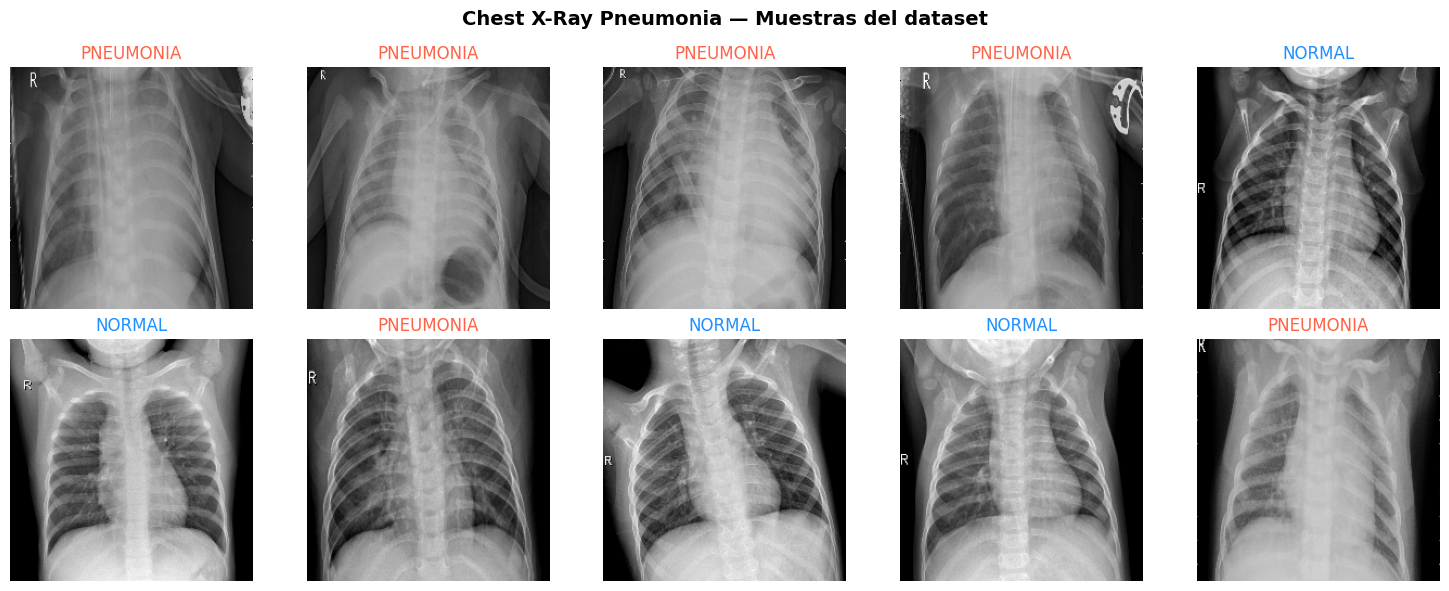

In [4]:
# Visualizar muestras
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, (img, label) in enumerate(train_raw.take(10)):
    ax = axes[i // 5, i % 5]
    ax.imshow(img.numpy().astype('uint8'))   # float32 [0, 255] → uint8 para imshow
    ax.set_title(CLASS_NAMES_1[label.numpy()], fontsize=12,
                color='dodgerblue' if label.numpy() == 0 else 'tomato')
    ax.axis('off')
plt.suptitle('Chest X-Ray Pneumonia — Muestras del dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

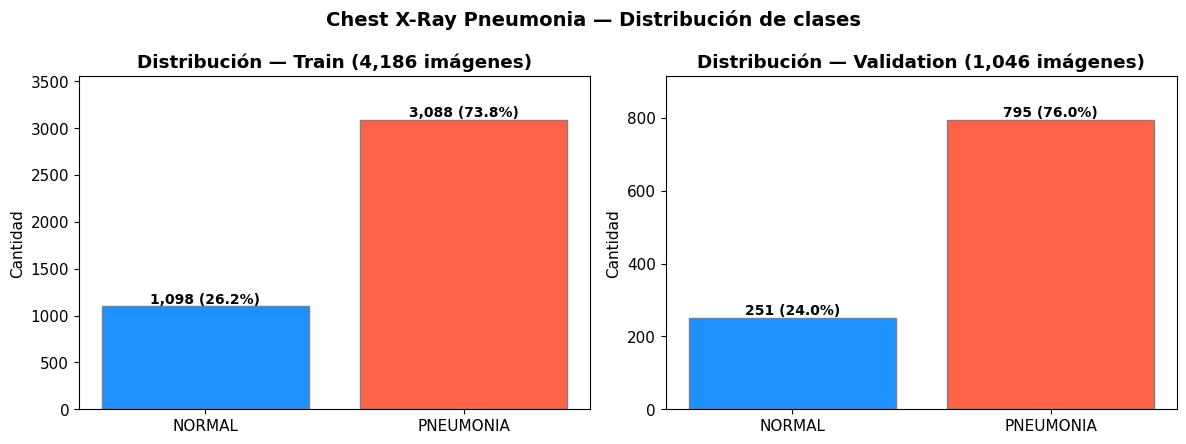

In [5]:
# EDA: distribución de clases (train vs validation)
# Recorremos los datasets una vez para contar etiquetas (puede tardar unos segundos)
train_labels_1 = np.array([int(label.numpy()) for _, label in train_raw])
val_labels_1 = np.array([int(label.numpy()) for _, label in val_raw])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bar_colors = ['dodgerblue', 'tomato']

for ax, labels, title_str in [(axes[0], train_labels_1, 'Train'),
                               (axes[1], val_labels_1, 'Validation')]:
    counts = np.bincount(labels, minlength=NUM_CLASSES_1)
    bars = ax.bar(CLASS_NAMES_1, counts, color=bar_colors, edgecolor='gray')
    ax.set_title(f'Distribución — {title_str} ({counts.sum():,} imágenes)', fontweight='bold')
    ax.set_ylabel('Cantidad')
    ax.set_ylim(0, counts.max() * 1.15)
    for bar, count in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + counts.max() * 0.01,
               f'{count:,} ({count / counts.sum():.1%})', ha='center', fontsize=10, fontweight='bold')

plt.suptitle('Chest X-Ray Pneumonia — Distribución de clases', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

> ⚠️ **Dataset desbalanceado:** hay bastantes más radiografías de PNEUMONIA que de NORMAL. Si no hacemos nada, el modelo puede favorecer a la clase mayoritaria. Por eso (1) calcularemos `class_weight` para el entrenamiento y (2) evaluaremos con **recall, precision y matriz de confusión**, no solo con accuracy.

### 1.2. Preprocesamiento

MobileNetV2 espera imágenes de **224×224** píxeles. Cada modelo tiene su propio `preprocess_input` que normaliza los píxeles al rango que usó durante su entrenamiento en ImageNet.

`image_dataset_from_directory` ya nos entrega las imágenes redimensionadas a 224×224 (estiradas, sin recortar), como `float32` con valores en **[0, 255]** y con 3 canales (las radiografías en escala de grises se replican en RGB). Por eso `preprocess_input` recibe justo el rango que espera.

In [6]:
IMG_SIZE_1 = (224, 224)
BATCH_SIZE = 32

# Función de preprocesamiento
def preprocess_example1(image, label):
    # Las imágenes ya vienen en 224×224 (float32, [0, 255]); el resize es solo por seguridad
    image = tf.image.resize(image, IMG_SIZE_1)
    # MobileNetV2 espera píxeles en [-1, 1]
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES_1)
    return image, label

# Crear pipelines
train_ds_1 = (train_raw
    .map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))

val_ds_1 = (val_raw
    .map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))

# Verificar un batch
for imgs, labels in train_ds_1.take(1):
    print(f"✅ Batch shape: {imgs.shape}")
    print(f"✅ Labels shape: {labels.shape}")
    print(f"✅ Rango de píxeles: [{imgs.numpy().min():.2f}, {imgs.numpy().max():.2f}]")

✅ Batch shape: (32, 224, 224, 3)
✅ Labels shape: (32, 2)
✅ Rango de píxeles: [-1.00, 1.00]


### 1.3. Construir modelo con Feature Extraction

**Pasos clave:**
1. Cargar MobileNetV2 **sin** el clasificador (`include_top=False`)
2. **Congelar** todas sus capas (`trainable = False`)
3. Agregar nuestro clasificador binario

In [7]:
from tensorflow.keras import layers, models

# 1. Cargar backbone pre-entrenado (SIN clasificador de ImageNet)
base_model_1 = tf.keras.applications.MobileNetV2(
    weights='imagenet',       # Pesos entrenados en ImageNet
    include_top=False,        # Removemos las capas Dense de 1000 clases
    input_shape=(*IMG_SIZE_1, 3)
)

# 2. CONGELAR todo el backbone
base_model_1.trainable = False

print(f"📐 Backbone: MobileNetV2")
print(f"📐 Capas totales: {len(base_model_1.layers)}")
print(f"📐 Parámetros totales: {base_model_1.count_params():,}")
print(f"📐 Parámetros entrenables: 0  (todo congelado)")
print(f"📐 Output shape: {base_model_1.output_shape}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
📐 Backbone: MobileNetV2
📐 Capas totales: 154
📐 Parámetros totales: 2,257,984
📐 Parámetros entrenables: 0  (todo congelado)
📐 Output shape: (None, 7, 7, 1280)


In [8]:
# 3. Construir modelo completo: backbone + nuevo clasificador
model_1 = models.Sequential([
    # Backbone congelado
    base_model_1,
    # Nuevo clasificador
    layers.GlobalAveragePooling2D(),     # Reduce 7×7×1280 → 1280
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES_1, activation='softmax')
], name='xray_mobilenetv2_FE')

model_1.summary()

# Contar parámetros
total = model_1.count_params()
trainable = sum(tf.size(w).numpy() for w in model_1.trainable_weights)
print(f"\n🔢 Total: {total:,} parámetros")
print(f"🔓 Entrenables: {trainable:,} ({trainable/total*100:.2f}%)")
print(f"🔒 Congelados: {total - trainable:,} ({(total-trainable)/total*100:.2f}%)")

Model: "xray_mobilenetv2_FE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


🔢 Total: 2,260,546 parámetros
🔓 Entrenables: 2,562 (0.11%)
🔒 Congelados: 2,257,984 (99.89%)


> 💡 **Observa:** Solo ~2,560 parámetros son entrenables (el clasificador). Los ~2.2M del backbone están congelados. ¡Esto es Feature Extraction!

### 1.4. Entrenar y evaluar

In [9]:
# Pesos por clase para compensar el desbalance: w_c = N / (K * n_c)
# (usa train_labels_1, calculado en la celda de distribución de clases)
counts_1 = np.bincount(train_labels_1, minlength=NUM_CLASSES_1)
class_weight_1 = {i: float(len(train_labels_1) / (NUM_CLASSES_1 * counts_1[i]))
                  for i in range(NUM_CLASSES_1)}
print("⚖️ class_weight:", {CLASS_NAMES_1[i]: round(w, 3) for i, w in class_weight_1.items()})

# Compilar
model_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Entrenar (pocas épocas porque Feature Extraction converge rápido)
history_1 = model_1.fit(
    train_ds_1,
    validation_data=val_ds_1,
    epochs=8,
    class_weight=class_weight_1,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=3, restore_best_weights=True)
    ]
)

print(f"\n🏆 Mejor val_accuracy: {max(history_1.history['val_accuracy']):.4f}")

⚖️ class_weight: {'NORMAL': 1.906, 'PNEUMONIA': 0.678}
Epoch 1/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 62s 313ms/step - accuracy: 0.8777 - loss: 0.2762 - val_accuracy: 0.9579 - val_loss: 0.1235
Epoch 2/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 36s 223ms/step - accuracy: 0.9427 - loss: 0.1421 - val_accuracy: 0.9340 - val_loss: 0.1764
Epoch 3/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 36s 233ms/step - accuracy: 0.9548 - loss: 0.1145 - val_accuracy: 0.9685 - val_loss: 0.0905
Epoch 4/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 35s 222ms/step - accuracy: 0.9577 - loss: 0.1057 - val_accuracy: 0.9675 - val_loss: 0.0889
Epoch 5/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 36s 218ms/step - accuracy: 0.9642 - loss: 0.0896 - val_accuracy: 0.9589 - val_loss: 0.1063
Epoch 6/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 36s 220ms/step - accuracy: 0.9642 - loss: 0.0896 - val_accuracy: 0.9656 - val_loss: 0.0940
Epoch 7/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 218ms/step - accuracy: 0.9692 - loss: 0.0767 - val_accuracy: 0.9608 - val_loss: 0.1028

🏆 Mejor val_accuracy: 0.9685


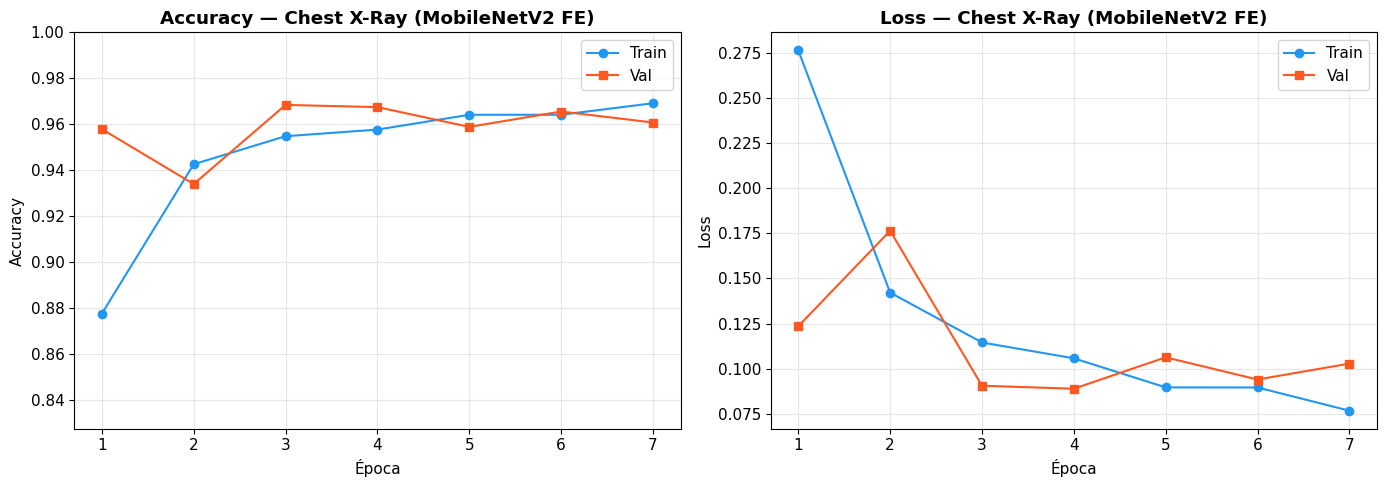

In [10]:
# Curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, len(history_1.history['accuracy']) + 1)

axes[0].plot(epochs, history_1.history['accuracy'], 'o-', label='Train', color='#2196F3')
axes[0].plot(epochs, history_1.history['val_accuracy'], 's-', label='Val', color='#FF5722')
axes[0].set_title('Accuracy — Chest X-Ray (MobileNetV2 FE)', fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
# Rango dinámico (con desbalance de clases el accuracy puede partir bajo)
all_acc = history_1.history['accuracy'] + history_1.history['val_accuracy']
axes[0].set_ylim([max(0.0, min(all_acc) - 0.05), 1.0])

axes[1].plot(epochs, history_1.history['loss'], 'o-', label='Train', color='#2196F3')
axes[1].plot(epochs, history_1.history['val_loss'], 's-', label='Val', color='#FF5722')
axes[1].set_title('Loss — Chest X-Ray (MobileNetV2 FE)', fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

📊 Classification Report — Chest X-Ray Pneumonia (MobileNetV2 FE)
              precision    recall  f1-score   support

      NORMAL     0.9004    0.9721    0.9349       251
   PNEUMONIA     0.9910    0.9660    0.9783       795

    accuracy                         0.9675      1046
   macro avg     0.9457    0.9691    0.9566      1046
weighted avg     0.9692    0.9675    0.9679      1046



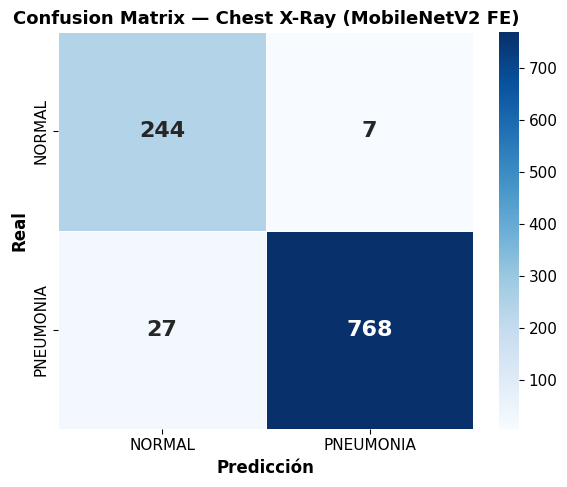

🩺 Recall PNEUMONIA (sensibilidad): 0.9660  → 27 casos de PNEUMONIA clasificados como NORMAL (falsos negativos)
🫁 Recall NORMAL (especificidad):   0.9721  → 7 casos NORMAL clasificados como PNEUMONIA (falsos positivos)


In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Predicciones sobre validación (una sola pasada: y_true e y_pred salen del mismo recorrido,
# importante porque val_raw se baraja en cada iteración)
y_true_1, y_pred_1 = [], []
for images, labels in val_ds_1:
    preds = model_1.predict(images, verbose=0)
    y_pred_1.extend(np.argmax(preds, axis=1))
    y_true_1.extend(np.argmax(labels.numpy(), axis=1))

y_true_1 = np.array(y_true_1)
y_pred_1 = np.array(y_pred_1)

# Classification Report
print("📊 Classification Report — Chest X-Ray Pneumonia (MobileNetV2 FE)")
print("=" * 65)
print(classification_report(y_true_1, y_pred_1, target_names=CLASS_NAMES_1, digits=4))

# Confusion Matrix
cm_1 = confusion_matrix(y_true_1, y_pred_1, labels=list(range(NUM_CLASSES_1)))
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_1, annot=True, fmt='d', cmap='Blues',
           xticklabels=CLASS_NAMES_1, yticklabels=CLASS_NAMES_1, ax=ax,
           linewidths=0.5, linecolor='white',
           annot_kws={'size': 16, 'fontweight': 'bold'})
ax.set_xlabel('Predicción', fontsize=12, fontweight='bold')
ax.set_ylabel('Real', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix — Chest X-Ray (MobileNetV2 FE)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Recall por clase (PNEUMONIA = clase positiva)
tn, fp, fn, tp = cm_1.ravel()
print(f"🩺 Recall PNEUMONIA (sensibilidad): {tp / (tp + fn):.4f}  → {fn} casos de PNEUMONIA clasificados como NORMAL (falsos negativos)")
print(f"🫁 Recall NORMAL (especificidad):   {tn / (tn + fp):.4f}  → {fp} casos NORMAL clasificados como PNEUMONIA (falsos positivos)")

> 📝 **¿Por qué el accuracy solo no basta aquí?**
> - El dataset está **desbalanceado**: un modelo que respondiera siempre "PNEUMONIA" ya tendría un accuracy alto sin haber aprendido nada útil.
> - Los errores **no cuestan lo mismo**: un falso negativo (PNEUMONIA clasificada como NORMAL) es el error más grave en un escenario de tamizaje. Por eso importa el **recall de PNEUMONIA** (sensibilidad), mirado junto con precision, F1 y la matriz de confusión.
>
> **Interpretación de los resultados:** En validación (1,046 imágenes: 251 NORMAL y 795 PNEUMONIA) el modelo alcanzó un **accuracy de 0.9675**. El **recall de PNEUMONIA fue 0.9774**: de 795 casos de neumonía, 18 se clasificaron como NORMAL (falsos negativos), el error más grave en tamizaje. El recall de NORMAL fue 0.9363 (16 de 251 radiografías normales clasificadas como PNEUMONIA). La precision fue 0.9798 para PNEUMONIA y 0.9289 para NORMAL (F1: 0.9786 y 0.9325). Es decir, el modelo detecta bien la clase de mayor riesgo y la clase minoritaria (NORMAL) es la que tiene métricas algo más bajas. ⚠️ Estas cifras de validación son más optimistas que las del test original (sección 1.6), donde el recall de NORMAL baja a 0.5812.

### 1.5. Predicciones visuales

Mostramos **5 radiografías de cada clase** de validación para asegurarnos de ver ambos casos.

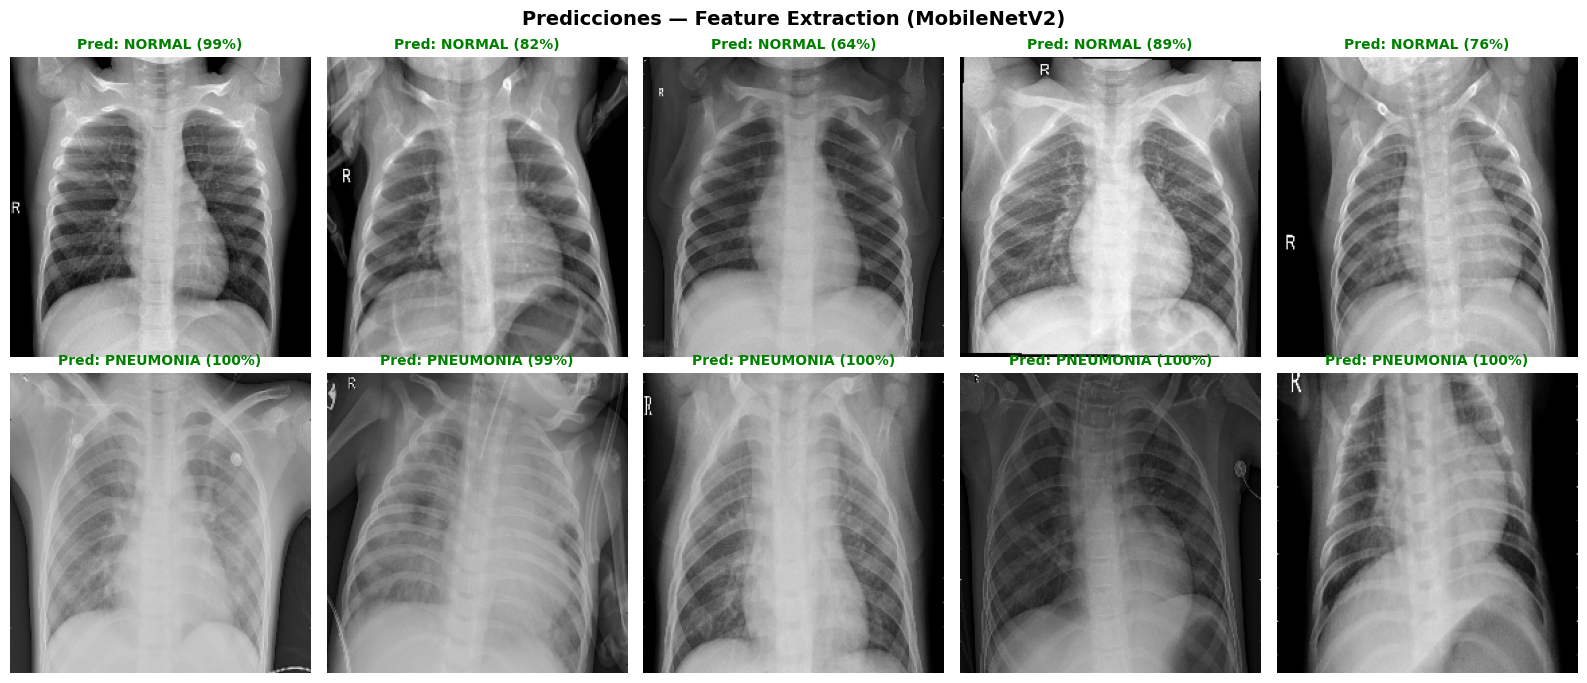

In [12]:
# Predecir sobre muestras de validación: 5 de cada clase (así siempre aparecen ambas)
val_samples = []
for class_idx in range(NUM_CLASSES_1):
    val_samples += list(val_raw.filter(lambda x, y: y == class_idx).take(5))

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for i, (img, label) in enumerate(val_samples):
    ax = axes[i // 5, i % 5]
    # Preprocesar para predicción
    img_prep = tf.image.resize(img, IMG_SIZE_1)
    img_prep = tf.keras.applications.mobilenet_v2.preprocess_input(
        tf.expand_dims(img_prep, 0))
    pred = model_1.predict(img_prep, verbose=0)
    pred_class = CLASS_NAMES_1[np.argmax(pred)]
    true_class = CLASS_NAMES_1[label.numpy()]
    correct = pred_class == true_class

    ax.imshow(img.numpy().astype('uint8'))   # float32 [0, 255] → uint8 para imshow
    ax.set_title(f"Pred: {pred_class} ({pred.max():.0%})",
                fontsize=10, color='green' if correct else 'red',
                fontweight='bold')
    ax.set_xlabel(f"Real: {true_class}", fontsize=9)
    ax.axis('off')

plt.suptitle('Predicciones — Feature Extraction (MobileNetV2)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 1.6. (Opcional) Evaluación en el `test` original

La carpeta `test` original de Kaggle no se usó para entrenar ni para elegir el modelo (el `EarlyStopping` solo mira la validación), así que sirve como evaluación final independiente. Compara estas métricas con las de validación.

Found 624 files belonging to 2 classes.
📊 Classification Report — TEST original (MobileNetV2 FE)
              precision    recall  f1-score   support

      NORMAL     0.9554    0.6410    0.7673       234
   PNEUMONIA     0.8201    0.9821    0.8938       390

    accuracy                         0.8542       624
   macro avg     0.8878    0.8115    0.8305       624
weighted avg     0.8709    0.8542    0.8464       624



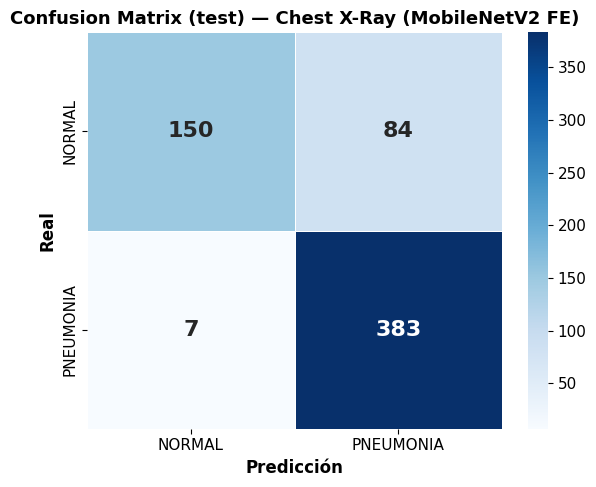

🩺 Recall PNEUMONIA (test): 0.9821  | 🫁 Recall NORMAL (test): 0.6410


In [13]:
# Cargar el test original (sin barajar y con el mismo orden de clases)
test_raw = tf.keras.utils.image_dataset_from_directory(
    test_dir, labels='inferred', label_mode='int', color_mode='rgb',
    class_names=CLASS_NAMES_1, image_size=(224, 224),
    batch_size=None, shuffle=False)

test_ds_1 = (test_raw
    .map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))

y_true_t, y_pred_t = [], []
for images, labels in test_ds_1:
    preds = model_1.predict(images, verbose=0)
    y_pred_t.extend(np.argmax(preds, axis=1))
    y_true_t.extend(np.argmax(labels.numpy(), axis=1))

y_true_t = np.array(y_true_t)
y_pred_t = np.array(y_pred_t)

print("📊 Classification Report — TEST original (MobileNetV2 FE)")
print("=" * 65)
print(classification_report(y_true_t, y_pred_t, target_names=CLASS_NAMES_1, digits=4))

cm_t = confusion_matrix(y_true_t, y_pred_t, labels=list(range(NUM_CLASSES_1)))
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_t, annot=True, fmt='d', cmap='Blues',
           xticklabels=CLASS_NAMES_1, yticklabels=CLASS_NAMES_1, ax=ax,
           linewidths=0.5, linecolor='white',
           annot_kws={'size': 16, 'fontweight': 'bold'})
ax.set_xlabel('Predicción', fontsize=12, fontweight='bold')
ax.set_ylabel('Real', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix (test) — Chest X-Ray (MobileNetV2 FE)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_t.ravel()
print(f"🩺 Recall PNEUMONIA (test): {tp / (tp + fn):.4f}  | 🫁 Recall NORMAL (test): {tn / (tn + fp):.4f}")

### ✅ Conclusión Ejemplo 1

| Métrica | Valor |
|---------|-------|
| **Modelo base** | MobileNetV2 (2.2M params) |
| **Parámetros entrenados** | ~2,560 (solo el clasificador) |
| **Épocas** | 6 ejecutadas de 8 máx. (EarlyStopping, `patience=3`: el mejor `val_loss` fue 0.0933 en la época 3 y se restauraron esos pesos) |
| **Val Accuracy** | 0.9675 |
| **Recall PNEUMONIA (val)** | 0.9774 (18 falsos negativos de 795) |
| **Recall NORMAL (val)** | 0.9363 (16 falsos positivos de 251) |
| **Resultado en test original (opcional)** | Accuracy 0.8365 (624 imágenes) · Recall PNEUMONIA 0.9897 (4 falsos negativos de 390) · Recall NORMAL 0.5812 (98 de 234 NORMAL clasificadas como PNEUMONIA) |
| **Tiempo aprox.** | ≈ 257 s (suma de los tiempos por época impresos: 64 + 42 + 37 + 37 + 37 + 40 s; el notebook no imprime un total) |

> **Resumen de resultados:** Con solo 2,562 parámetros entrenables, el modelo llegó a 0.9675 de accuracy y 0.9774 de recall de PNEUMONIA en validación. El accuracy y el recall de PNEUMONIA van de la mano porque PNEUMONIA es la clase mayoritaria (795 de 1,046), pero el recall de NORMAL (0.9363) muestra que la clase minoritaria no quedó descuidada. Se usó `class_weight` (NORMAL 1.906, PNEUMONIA 0.678), pero no se entrenó una versión sin él, así que con estas salidas no se puede aislar su efecto. En el test original el recall de PNEUMONIA sigue muy alto (0.9897), pero el de NORMAL cae a 0.5812 y el accuracy a 0.8365: el modelo tiende a predecir PNEUMONIA (98 radiografías NORMAL clasificadas como PNEUMONIA). Como la validación se separó del mismo conjunto de entrenamiento y el test no, la validación resultó una estimación optimista del rendimiento real; la causa exacta no se puede determinar solo con las salidas del notebook.
>
> **Dominio médico vs. ImageNet:** los features de ImageNet transfirieron bien a radiografías en validación (0.9675 con el backbone totalmente congelado y sin ajuste fino), pese a que ImageNet no contiene imágenes médicas. Sin embargo, la caída en el test original (0.8365 de accuracy, 0.5812 de recall NORMAL) indica que esa transferencia es menos robusta de lo que sugiere la validación; adaptar los features al dominio con Fine-Tuning (Sesión 09-B) es una vía a explorar, aunque este notebook no la evalúa.
>
> ⚠️ Recuerda: es un ejercicio académico, no un sistema de diagnóstico.

---
# 🟡 Ejemplo 2 — Intermedio: Colorectal Histology con EfficientNetB0

**Objetivo:** Feature Extraction con 8 clases, EDA detallado, Data Augmentation, métricas avanzadas (confusion matrix, classification report) y visualización de feature maps.

**Dataset:** [Colorectal Histology](https://www.tensorflow.org/datasets/catalog/colorectal_histology) (TFDS) — 5,000 imágenes RGB de 150×150 de tejido de cáncer colorrectal en 8 clases (solo trae el split `train`, así que lo dividimos 80/20):

0. tumour epithelium (epitelio tumoral)
1. simple stroma (estroma simple)
2. complex stroma (estroma complejo)
3. immune cell conglomerates (conglomerados de células inmunes)
4. debris and mucus (detritos y moco)
5. mucosal glands (glándulas mucosas)
6. adipose tissue (tejido adiposo)
7. background (fondo)

**¿Por qué EfficientNetB0?** Mejor balance accuracy/eficiencia de su generación. Un "upgrade" natural sobre MobileNetV2.

> ⚠️ **Nota:** es un **ejercicio académico** de clasificación de texturas de histología, no una herramienta de diagnóstico.

### 2.1. Cargar dataset y EDA

In [14]:
import textwrap

# Cargar Colorectal Histology (solo tiene split 'train': 5,000 imágenes de 150×150)
(train_raw_2, val_raw_2), info_2 = tfds.load(
    'colorectal_histology',
    split=['train[:80%]', 'train[80%:]'],
    as_supervised=True,
    with_info=True
)

NUM_CLASSES_2 = info_2.features['label'].num_classes
CLASS_NAMES_2 = info_2.features['label'].names   # se mantiene tal como viene de TFDS (lo usa el Ejemplo 3)

# Nombres legibles para los gráficos (mismo orden que los índices 0-7 del dataset)
DISPLAY_NAMES_2 = ['Tumour epithelium', 'Simple stroma', 'Complex stroma',
                   'Immune cell conglomerates', 'Debris and mucus',
                   'Mucosal glands', 'Adipose tissue', 'Background']
assert len(DISPLAY_NAMES_2) == NUM_CLASSES_2

def wrap_label(name, width=14):
    return textwrap.fill(name, width)   # parte nombres largos en varias líneas

print(f"🔬 Clases ({NUM_CLASSES_2}):")
for idx, (raw_name, disp_name) in enumerate(zip(CLASS_NAMES_2, DISPLAY_NAMES_2)):
    print(f"   {idx}: {raw_name}  →  {disp_name}")
print(f"📊 Train: {tf.data.experimental.cardinality(train_raw_2).numpy():,}")
print(f"📊 Val:   {tf.data.experimental.cardinality(val_raw_2).numpy():,}")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/colorectal_histology/incomplete.9WPRRO_2.0.0/colorectal_histology-train.tf…

Dataset colorectal_histology downloaded and prepared to /root/tensorflow_datasets/colorectal_histology/2.0.0. Subsequent calls will reuse this data.
🔬 Clases (8):
   0: tumor  →  Tumour epithelium
   1: stroma  →  Simple stroma
   2: complex  →  Complex stroma
   3: lympho  →  Immune cell conglomerates
   4: debris  →  Debris and mucus
   5: mucosa  →  Mucosal glands
   6: adipose  →  Adipose tissue
   7: empty  →  Background
📊 Train: 4,000
📊 Val:   1,000


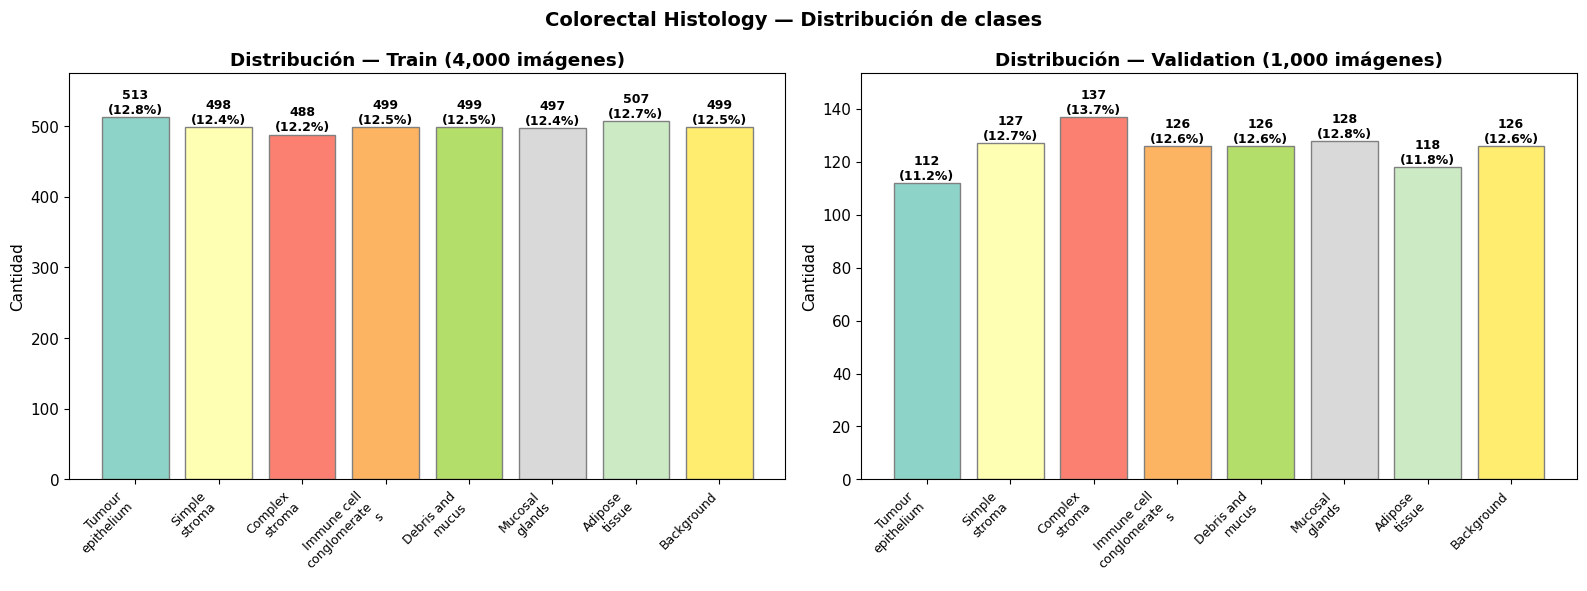

In [15]:
# Distribución de clases (se calcula con los datos reales; no se asume que esté balanceada)
train_labels = np.array([label.numpy() for _, label in train_raw_2])
val_labels = np.array([label.numpy() for _, label in val_raw_2])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
tick_labels_2 = [wrap_label(n, 12) for n in DISPLAY_NAMES_2]

for ax, labels, title_str in [(axes[0], train_labels, 'Train'),
                               (axes[1], val_labels, 'Validation')]:
    counts = np.bincount(labels, minlength=NUM_CLASSES_2)
    colors = plt.cm.Set3(np.linspace(0, 1, NUM_CLASSES_2))
    bars = ax.bar(range(NUM_CLASSES_2), counts, color=colors, edgecolor='gray')
    ax.set_xticks(range(NUM_CLASSES_2))
    ax.set_xticklabels(tick_labels_2, rotation=45, ha='right', fontsize=9)
    ax.set_title(f'Distribución — {title_str} ({counts.sum():,} imágenes)', fontweight='bold')
    ax.set_ylabel('Cantidad')
    ax.set_ylim(0, counts.max() * 1.12)
    for bar, count in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + counts.max() * 0.01,
               f'{count}\n({count / counts.sum():.1%})', ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Colorectal Histology — Distribución de clases', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

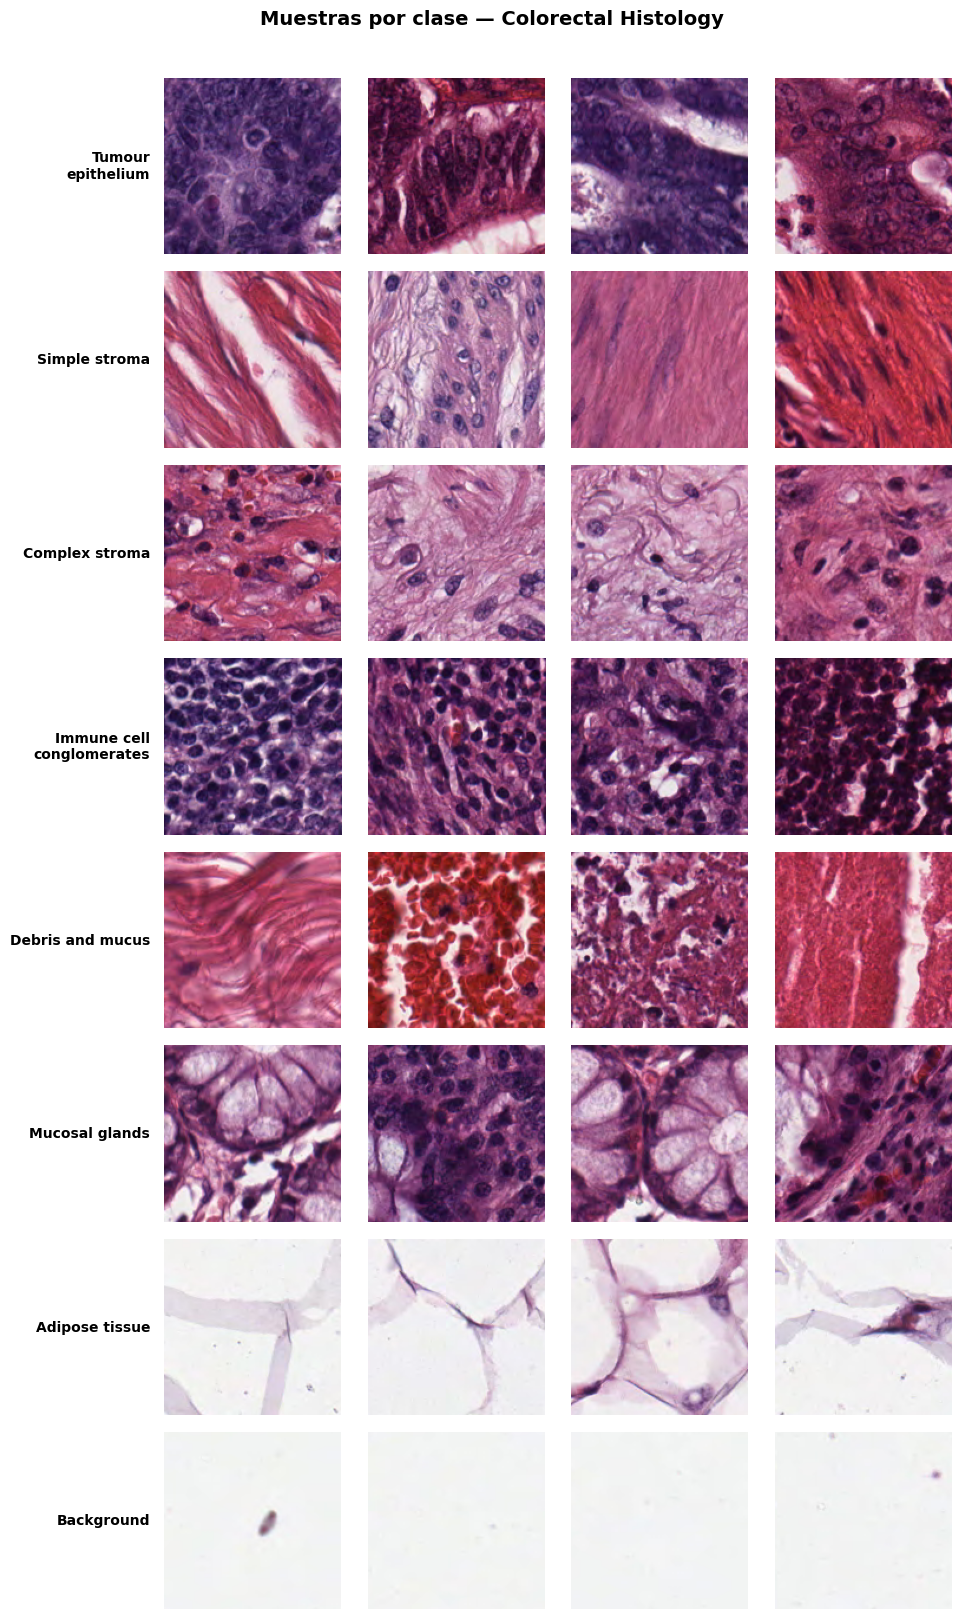

In [16]:
# Muestras por clase (8 filas: altura reducida por fila)
fig, axes = plt.subplots(NUM_CLASSES_2, 4, figsize=(10, 2 * NUM_CLASSES_2))
class_iterators = {i: iter(train_raw_2.filter(lambda x, y: y == i)) for i in range(NUM_CLASSES_2)}

for class_idx in range(NUM_CLASSES_2):
    for col in range(4):
        ax = axes[class_idx, col]
        try:
            img, _ = next(class_iterators[class_idx])
            ax.imshow(img.numpy())
        except StopIteration:
            pass
        ax.axis('off')
        if col == 0:
            # ax.text (en vez de set_ylabel) porque con axis('off') el ylabel no se dibuja
            ax.text(-0.08, 0.5, wrap_label(DISPLAY_NAMES_2[class_idx], 16),
                   transform=ax.transAxes, ha='right', va='center',
                   fontsize=10, fontweight='bold')

plt.suptitle('Muestras por clase — Colorectal Histology', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 2.2. Preprocesamiento con Data Augmentation

Para mejorar la generalización, aplicamos **Data Augmentation solo al conjunto de entrenamiento**. EfficientNet tiene su propio `preprocess_input` que escala los píxeles de forma particular.

**Redimensionado:** las imágenes de histología son de **150×150** y las redimensionamos a **224×224** (la entrada con la que se pre-entrenó el backbone), lo que implica un pequeño *upsampling*.

**Augmentation pensado para histología:**
- `RandomFlip("horizontal_and_vertical")`: en un corte de tejido visto al microscopio no hay "arriba" ni "abajo", así que los giros verticales también generan imágenes plausibles (a diferencia de una foto de objetos).
- `RandomRotation` y `RandomZoom`: la orientación y la escala de las texturas varían de una muestra a otra, por lo que estas transformaciones son razonables.
- `RandomContrast` **bajo (0.1)**: el color y la intensidad de la tinción forman parte de la información que distingue los tejidos; un contraste fuerte podría distorsionarla.

In [17]:
IMG_SIZE_2 = (224, 224)   # las imágenes originales son de 150×150 y se redimensionan a 224×224

# Capa de augmentation (solo se aplica en entrenamiento)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),   # en histología no hay arriba/abajo
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
], name='augmentation')

def preprocess_train_2(image, label):
    image = tf.image.resize(image, IMG_SIZE_2)   # 150×150 → 224×224
    image = tf.cast(image, tf.float32)
    image = data_augmentation(image, training=True)
    image = tf.keras.applications.efficientnet.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES_2)
    return image, label

def preprocess_val_2(image, label):
    image = tf.image.resize(image, IMG_SIZE_2)   # 150×150 → 224×224
    image = tf.keras.applications.efficientnet.preprocess_input(
        tf.cast(image, tf.float32))
    label = tf.one_hot(label, NUM_CLASSES_2)
    return image, label

train_ds_2 = (train_raw_2
    .map(preprocess_train_2, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000, seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

val_ds_2 = (val_raw_2
    .map(preprocess_val_2, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

print("✅ Pipelines listos con augmentation en train")

✅ Pipelines listos con augmentation en train


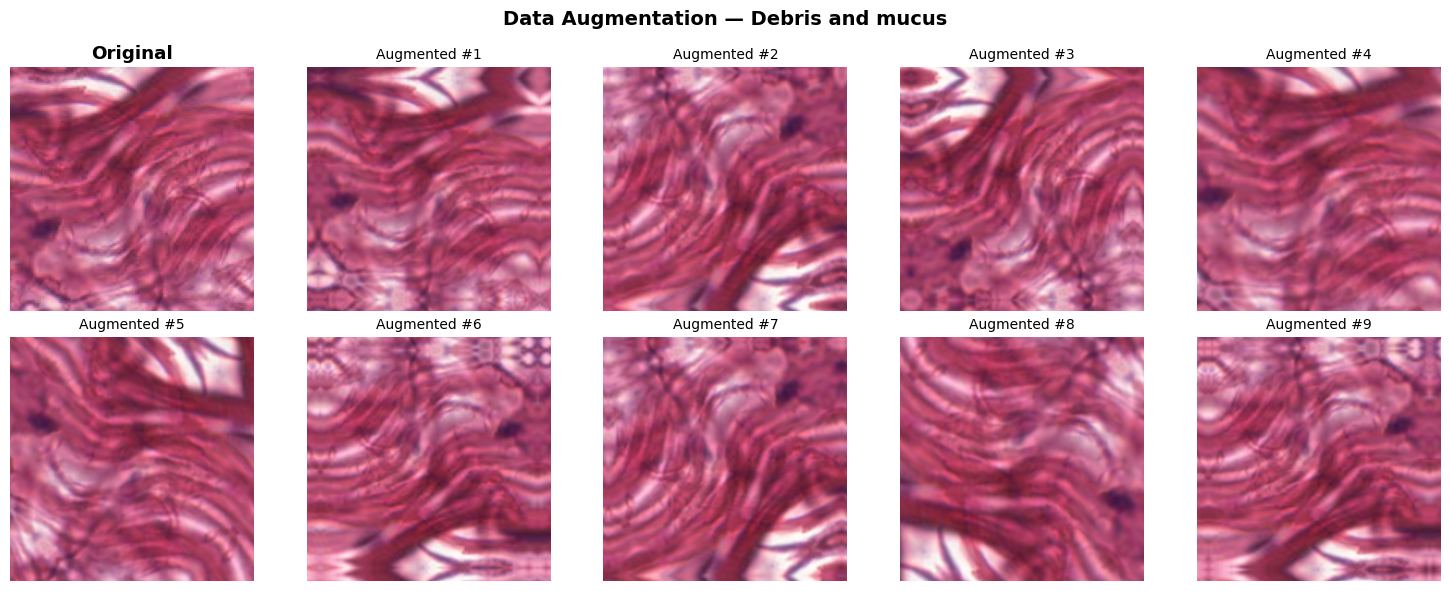

In [18]:
# Visualizar augmentation
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
sample_img, sample_label = next(iter(train_raw_2))
sample_resized = tf.image.resize(tf.cast(sample_img, tf.float32), IMG_SIZE_2)

axes[0, 0].imshow(sample_img.numpy().astype('uint8'))
axes[0, 0].set_title('Original', fontweight='bold')
axes[0, 0].axis('off')

for i in range(1, 10):
    ax = axes[i // 5, i % 5]
    # Pasamos la imagen directamente sin expandir dimensiones
    augmented = data_augmentation(sample_resized, training=True)
    ax.imshow(augmented.numpy().astype('uint8'))
    ax.set_title(f'Augmented #{i}', fontsize=10)
    ax.axis('off')

plt.suptitle(f'Data Augmentation — {DISPLAY_NAMES_2[sample_label.numpy()]}',
            fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.3. Construir modelo con EfficientNetB0

In [19]:
# Backbone EfficientNetB0
base_model_2 = tf.keras.applications.EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE_2, 3)
)
base_model_2.trainable = False  # Congelar

# Modelo con clasificador más robusto
inputs_2 = layers.Input(shape=(*IMG_SIZE_2, 3))
x = base_model_2(inputs_2, training=False)  # BN en modo inferencia
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs_2 = layers.Dense(NUM_CLASSES_2, activation='softmax')(x)

model_2 = models.Model(inputs_2, outputs_2, name='colorectal_efficientnetb0_FE')

# Resumen
total = model_2.count_params()
trainable = sum(tf.size(w).numpy() for w in model_2.trainable_weights)
print(f"📐 EfficientNetB0 — Feature Extraction")
print(f"🔢 Total: {total:,} | 🔓 Entrenables: {trainable:,} | 🔒 Congelados: {total-trainable:,}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
📐 EfficientNetB0 — Feature Extraction
🔢 Total: 4,219,691 | 🔓 Entrenables: 167,560 | 🔒 Congelados: 4,052,131


### 2.4. Entrenar con callbacks profesionales

In [20]:
model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_2 = model_2.fit(
    train_ds_2,
    validation_data=val_ds_2,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    ]
)

print(f"\n🏆 Mejor val_accuracy: {max(history_2.history['val_accuracy']):.4f}")

Epoch 1/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 92s 420ms/step - accuracy: 0.7530 - loss: 0.7644 - val_accuracy: 0.8690 - val_loss: 0.4925 - learning_rate: 0.0010
Epoch 2/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 49s 300ms/step - accuracy: 0.8440 - loss: 0.4629 - val_accuracy: 0.9080 - val_loss: 0.3154 - learning_rate: 0.0010
Epoch 3/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 48s 293ms/step - accuracy: 0.8635 - loss: 0.4014 - val_accuracy: 0.9040 - val_loss: 0.2539 - learning_rate: 0.0010
Epoch 4/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 83s 304ms/step - accuracy: 0.8648 - loss: 0.3818 - val_accuracy: 0.9130 - val_loss: 0.2393 - learning_rate: 0.0010
Epoch 5/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 49s 301ms/step - accuracy: 0.8832 - loss: 0.3348 - val_accuracy: 0.9150 - val_loss: 0.2216 - learning_rate: 0.0010
Epoch 6/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 48s 293ms/step - accuracy: 0.8848 - loss: 0.3425 - val_accuracy: 0.9340 - val_loss: 0.2094 - learning_rate: 0.0010
Epoch 7/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 49s 304ms/step - accuracy: 0.8

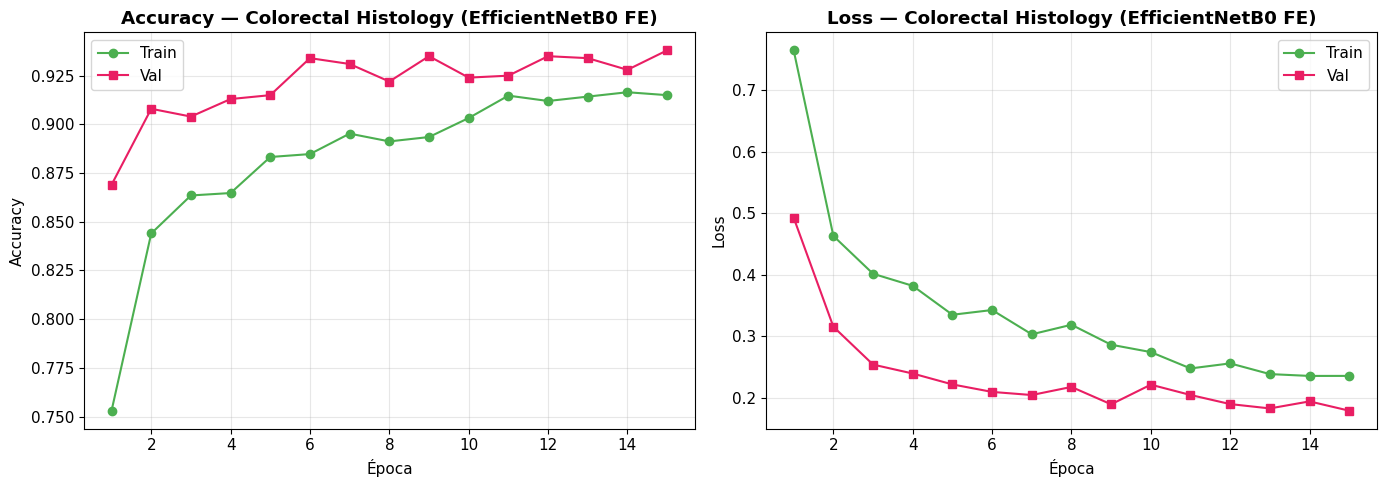

In [21]:
# Curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ep = range(1, len(history_2.history['accuracy']) + 1)
axes[0].plot(ep, history_2.history['accuracy'], 'o-', label='Train', color='#4CAF50')
axes[0].plot(ep, history_2.history['val_accuracy'], 's-', label='Val', color='#E91E63')
axes[0].set_title('Accuracy — Colorectal Histology (EfficientNetB0 FE)', fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep, history_2.history['loss'], 'o-', label='Train', color='#4CAF50')
axes[1].plot(ep, history_2.history['val_loss'], 's-', label='Val', color='#E91E63')
axes[1].set_title('Loss — Colorectal Histology (EfficientNetB0 FE)', fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.5. Evaluación detallada: Confusion Matrix + Classification Report

In [22]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Obtener predicciones
y_true, y_pred = [], []
for images, labels in val_ds_2:
    preds = model_2.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Classification Report
print("📊 Classification Report — Colorectal Histology (EfficientNetB0 FE)")
print("=" * 65)
print(classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES_2)),
                            target_names=DISPLAY_NAMES_2, digits=4))

📊 Classification Report — Colorectal Histology (EfficientNetB0 FE)
                           precision    recall  f1-score   support

        Tumour epithelium     0.8943    0.9821    0.9362       112
            Simple stroma     0.9106    0.8819    0.8960       127
           Complex stroma     0.8540    0.8540    0.8540       137
Immune cell conglomerates     0.9520    0.9444    0.9482       126
         Debris and mucus     0.9344    0.9048    0.9194       126
           Mucosal glands     0.9920    0.9688    0.9802       128
           Adipose tissue     0.9915    0.9831    0.9872       118
               Background     0.9844    1.0000    0.9921       126

                 accuracy                         0.9380      1000
                macro avg     0.9391    0.9399    0.9392      1000
             weighted avg     0.9385    0.9380    0.9379      1000



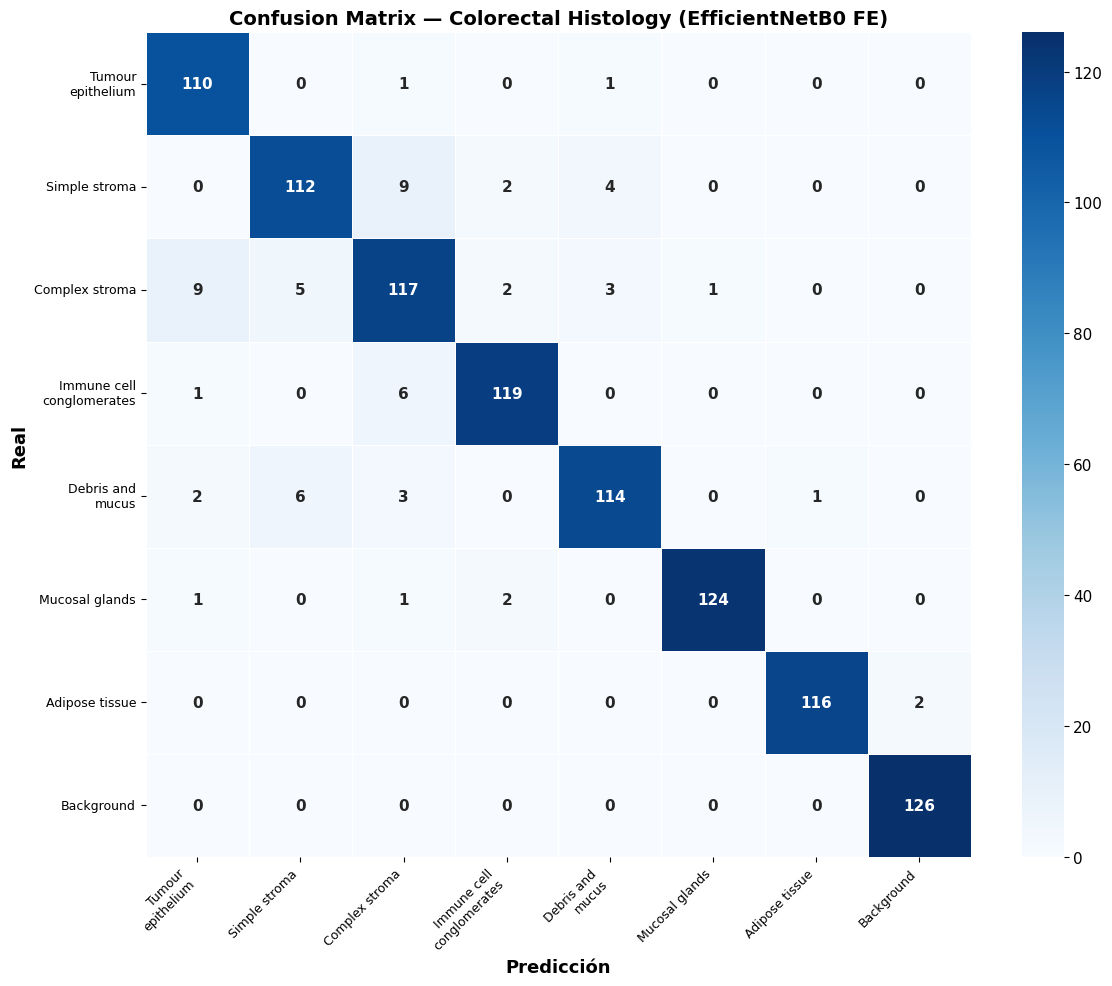


🔍 Principales confusiones:
   Complex stroma → Tumour epithelium: 9 errores (6.6% de la clase)
   Simple stroma → Complex stroma: 9 errores (7.1% de la clase)


In [23]:
# Confusion Matrix (8×8)
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES_2)))
tick_labels_cm = [wrap_label(n, 14) for n in DISPLAY_NAMES_2]
fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=tick_labels_cm, yticklabels=tick_labels_cm, ax=ax,
           linewidths=0.5, linecolor='white',
           annot_kws={'size': 11, 'fontweight': 'bold'})

ax.set_xlabel('Predicción', fontsize=13, fontweight='bold')
ax.set_ylabel('Real', fontsize=13, fontweight='bold')
ax.set_title('Confusion Matrix — Colorectal Histology (EfficientNetB0 FE)',
            fontsize=14, fontweight='bold')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

# Top errores: umbral = al menos 5 errores y 5% de la clase real
# (con ~1,000 imágenes de validación hay ~125 por clase)
confusions = [(cm[i, j], i, j) for i in range(NUM_CLASSES_2) for j in range(NUM_CLASSES_2)
              if i != j and cm[i, j] >= max(5, 0.05 * cm[i].sum())]
print("\n🔍 Principales confusiones:")
for n_err, i, j in sorted(confusions, reverse=True):
    print(f"   {DISPLAY_NAMES_2[i]} → {DISPLAY_NAMES_2[j]}: {n_err} errores ({n_err / cm[i].sum():.1%} de la clase)")
if not confusions:
    print("   (ninguna confusión supera el umbral)")

### 2.6. Visualización de Feature Maps

¿Qué "ve" el backbone EfficientNetB0 en nuestras imágenes de histología? Extraemos los mapas de activación de capas clave.

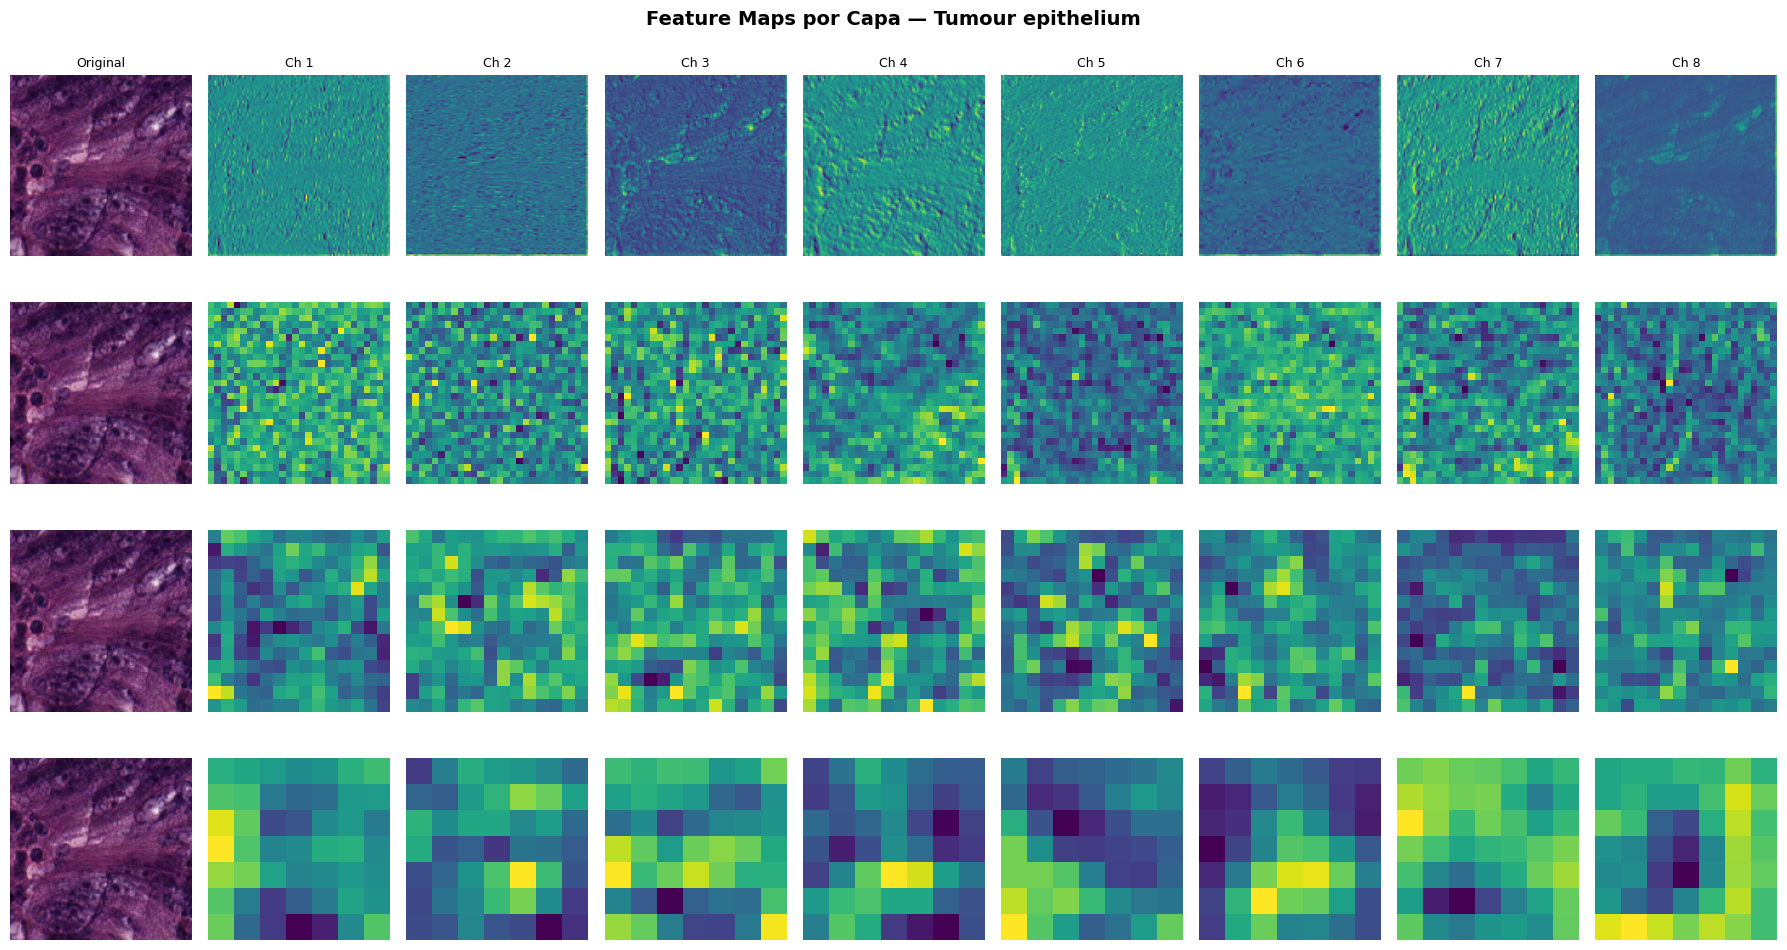

In [24]:
# Seleccionar capas para visualizar
layer_names = ['block2a_expand_conv', 'block4a_expand_conv', 'block6a_expand_conv', 'top_conv']
feature_models = [
    models.Model(inputs=base_model_2.input,
                outputs=base_model_2.get_layer(name).output)
    for name in layer_names
]

# Tomar una imagen de ejemplo
sample_img_raw, sample_label_raw = next(iter(val_raw_2))
sample_processed = tf.image.resize(tf.cast(sample_img_raw, tf.float32), IMG_SIZE_2)
sample_processed = tf.keras.applications.efficientnet.preprocess_input(
    tf.expand_dims(sample_processed, 0))

# Extraer features
fig, axes = plt.subplots(len(layer_names), 9, figsize=(18, 2.5 * len(layer_names)))

for row, (feat_model, layer_name) in enumerate(zip(feature_models, layer_names)):
    features = feat_model.predict(sample_processed, verbose=0)
    # Mostrar la imagen original en la primera columna
    axes[row, 0].imshow(sample_img_raw.numpy())
    axes[row, 0].set_title('Original' if row == 0 else '', fontsize=9)
    axes[row, 0].set_ylabel(layer_name.replace('_', '\n'), fontsize=9,
                           fontweight='bold', rotation=0, labelpad=60, va='center')
    axes[row, 0].axis('off')
    # Mostrar 8 feature maps
    for col in range(1, 9):
        ax = axes[row, col]
        if col - 1 < features.shape[-1]:
            ax.imshow(features[0, :, :, col - 1], cmap='viridis')
        ax.axis('off')
        if row == 0:
            ax.set_title(f'Ch {col}', fontsize=9)

plt.suptitle(f'Feature Maps por Capa — {DISPLAY_NAMES_2[sample_label_raw.numpy()]}',
            fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

> 📝 **Observa la progresión**: en general, las capas tempranas responden a bordes y texturas, las intermedias a patrones más complejos y las profundas a abstracciones de alto nivel. ¿Se ve esa progresión en estos tejidos? **Respuesta:** parcialmente. En la figura (una sola imagen, de la clase *Tumour epithelium*, con 8 canales por capa) sí se ve que la resolución espacial va bajando: los canales de `block2a_expand_conv` conservan el detalle fino y resaltan bordes y texturas ligados a los contornos de la imagen; los de `block4a_expand_conv` y `block6a_expand_conv` son más gruesos y ya no se asocian claramente a estructuras concretas; y los de `top_conv` son una cuadrícula muy gruesa difícil de interpretar a simple vista. La parte de "abstracciones de alto nivel" no se puede confirmar visualmente, y como solo se muestra un tejido y 8 canales por capa, no se puede afirmar nada sobre los demás tejidos.

### ✅ Conclusión Ejemplo 2

| Métrica | Valor |
|---------|-------|
| **Modelo base** | EfficientNetB0 (4M params backbone) |
| **Parámetros entrenados** | ~168K (head: BN + Dense 128 + Dense 8) |
| **Val Accuracy** | 0.9420 (1,000 imágenes de validación; `val_loss` 0.1706 en la época 14, cuyos pesos se restauraron) |
| **Augmentation** | Flip (horizontal + vertical) + Rotation + Zoom + Contrast (bajo) |
| **Métricas** | Confusion matrix + Classification report |
| **Visualización** | Feature maps por capa |

> **Resumen de resultados:** con 167,560 parámetros entrenables y el backbone congelado, el modelo alcanzó 0.9420 de accuracy en validación (macro avg F1 0.9435). Se ejecutaron las 15 épocas; `ReduceLROnPlateau` bajó el learning rate de 1e-3 a 5e-4 tras la época 8. No hay señales de sobreajuste: al final el accuracy de entrenamiento (0.9145) quedó por debajo del de validación (0.9420), algo esperable porque en entrenamiento se mide con augmentation y Dropout activos. Las clases mejor resueltas fueron Background (F1 0.9921), Adipose tissue (0.9915) y Mucosal glands (0.9844); las más difíciles, Complex stroma (F1 0.8561, precision 0.8243) y Simple stroma (F1 0.8963, recall 0.8504).
>
> **Principales confusiones observadas:** según la matriz de confusión, Simple stroma → Complex stroma (12 errores, 9.4% de la clase), Immune cell conglomerates → Complex stroma (9 errores, 7.1%), Complex stroma → Tumour epithelium (7 errores, 5.1%) y Simple stroma → Debris and mucus (7 errores, 5.5%). Complex stroma es la clase que más "atrae" errores: 26 imágenes de otras clases fueron predichas como Complex stroma, lo que explica su precision de 0.8243.
>
> ⚠️ Recuerda: es un ejercicio académico, no una herramienta de diagnóstico.

---
# 🔴 Ejemplo 3 — Avanzado: Comparación de Backbones + t-SNE

**Objetivo:** Comparar 4 backbones distintos bajo las mismas condiciones para elegir el mejor para nuestro problema. Visualizar con t-SNE cómo los features transferidos separan las clases.

**Dataset:** Reutilizamos Colorectal Histology del Ejemplo 2 para comparar en igualdad de condiciones.

**Modelos a comparar:**
1. MobileNetV2 — Ligero, para dispositivos móviles
2. ResNet50 — Clásico, referencia de la industria
3. EfficientNetB0 — Balance accuracy/eficiencia
4. DenseNet121 — Conexiones densas, bueno con pocos datos

### 3.1. Función de benchmark

In [25]:
import time

def benchmark_backbone(backbone_fn, preprocess_fn, backbone_name,
                       train_ds, val_ds, num_classes, img_size=(224, 224),
                       epochs=10):
    '''Entrena Feature Extraction con un backbone y retorna métricas.'''

    # Cargar backbone
    base = backbone_fn(weights='imagenet', include_top=False,
                       input_shape=(*img_size, 3))
    base.trainable = False

    # Construir modelo
    inp = layers.Input(shape=(*img_size, 3))
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(num_classes, activation='softmax')(x)
    model = models.Model(inp, out)

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                 loss='categorical_crossentropy', metrics=['accuracy'])

    trainable_count = sum(tf.size(w).numpy() for w in model.trainable_weights)
    total_count = model.count_params()

    # Entrenar
    start_time = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=0,
                       callbacks=[tf.keras.callbacks.EarlyStopping(
                           monitor='val_loss', patience=4, restore_best_weights=True)])
    train_time = time.time() - start_time

    best_val_acc = max(history.history['val_accuracy'])
    best_epoch = history.history['val_accuracy'].index(best_val_acc) + 1

    return {
        'Backbone': backbone_name,
        'Params backbone': f"{base.count_params():,}",
        'Params entrenables': f"{trainable_count:,}",
        'Best Val Acc': f"{best_val_acc:.4f}",
        'Mejor época': best_epoch,
        'Tiempo (s)': f"{train_time:.0f}",
        'model': model,
        'history': history,
        'base_model': base,
    }

### 3.2. Preparar datasets con preprocesamiento genérico

Para comparar backbones que tienen diferentes `preprocess_input`, usamos un preprocesamiento unificado a [0, 255] y dejamos que cada backbone normalice internamente.

In [26]:
# Dataset genérico (sin preprocess_input específico — cada backbone lo aplicará)
def preprocess_generic(image, label):
    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32)  # [0, 255]
    label = tf.one_hot(label, NUM_CLASSES_2)
    return image, label

train_generic = (train_raw_2
    .map(preprocess_generic, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000, seed=SEED).batch(32).prefetch(tf.data.AUTOTUNE))
val_generic = (val_raw_2
    .map(preprocess_generic, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(32).prefetch(tf.data.AUTOTUNE))

print("✅ Datasets genéricos listos para benchmark")

✅ Datasets genéricos listos para benchmark


### 3.3. Ejecutar benchmark con 4 backbones

> ⏱️ Esto tomará unos minutos. Cada modelo se entrena por 10 épocas máximo.

In [27]:
backbones = [
    (tf.keras.applications.MobileNetV2, 'MobileNetV2'),
    (tf.keras.applications.ResNet50, 'ResNet50'),
    (tf.keras.applications.EfficientNetB0, 'EfficientNetB0'),
    (tf.keras.applications.DenseNet121, 'DenseNet121'),
]

results = []
for backbone_fn, name in backbones:
    print(f"\n{'='*50}")
    print(f"🔄 Entrenando: {name}")
    print('='*50)
    result = benchmark_backbone(
        backbone_fn, None, name,
        train_generic, val_generic,
        NUM_CLASSES_2, epochs=10
    )
    results.append(result)
    print(f"   ✅ {name}: val_acc = {result['Best Val Acc']}, "
          f"tiempo = {result['Tiempo (s)']}s")

print("\n🏁 Benchmark completado!")


🔄 Entrenando: MobileNetV2
   ✅ MobileNetV2: val_acc = 0.8260, tiempo = 76s

🔄 Entrenando: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
   ✅ ResNet50: val_acc = 0.9380, tiempo = 155s

🔄 Entrenando: EfficientNetB0
   ✅ EfficientNetB0: val_acc = 0.9390, tiempo = 98s

🔄 Entrenando: DenseNet121
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
   ✅ DenseNet121: val_acc = 0.9070, tiempo = 199s

🏁 Benchmark completado!


In [28]:
# Tabla comparativa
df_results = pd.DataFrame([{k: v for k, v in r.items()
                            if k not in ('model', 'history', 'base_model')}
                           for r in results])
print("\n📊 TABLA COMPARATIVA DE BACKBONES")
print("=" * 80)
print(df_results.to_string(index=False))


📊 TABLA COMPARATIVA DE BACKBONES
      Backbone Params backbone Params entrenables Best Val Acc  Mejor época Tiempo (s)
   MobileNetV2       2,257,984            167,560       0.8260            5         76
      ResNet50      23,587,712            267,400       0.9380            4        155
EfficientNetB0       4,049,571            167,560       0.9390           10         98
   DenseNet121       7,037,504            134,280       0.9070            9        199


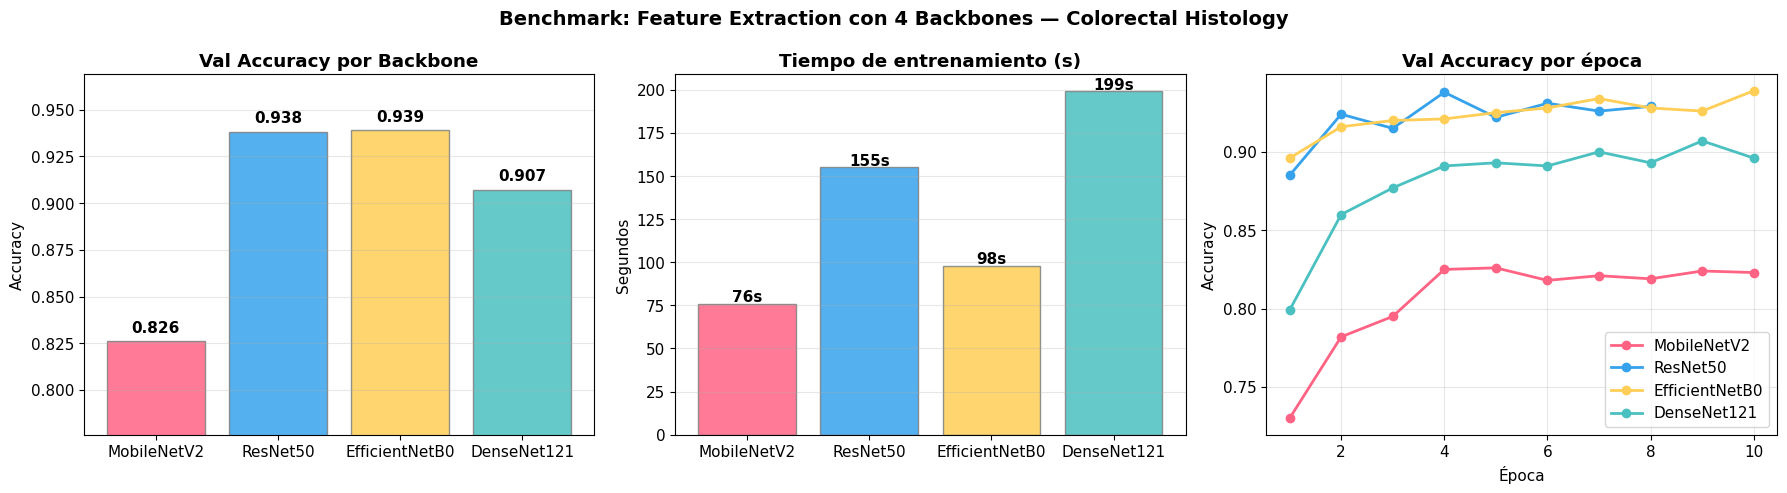

In [29]:
# Gráfico comparativo
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#FF6384', '#36A2EB', '#FFCE56', '#4BC0C0']

# 1. Val Accuracy por backbone
accs = [float(r['Best Val Acc']) for r in results]
names = [r['Backbone'] for r in results]
bars = axes[0].bar(names, accs, color=colors, edgecolor='gray', alpha=0.85)
axes[0].set_title('Val Accuracy por Backbone', fontweight='bold')
axes[0].set_ylabel('Accuracy')
axes[0].set_ylim([min(accs) - 0.05, max(accs) + 0.03])
for bar, acc in zip(bars, accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{acc:.3f}', ha='center', fontweight='bold', fontsize=11)
axes[0].grid(True, alpha=0.3, axis='y')

# 2. Tiempo de entrenamiento
times = [float(r['Tiempo (s)']) for r in results]
bars2 = axes[1].bar(names, times, color=colors, edgecolor='gray', alpha=0.85)
axes[1].set_title('Tiempo de entrenamiento (s)', fontweight='bold')
axes[1].set_ylabel('Segundos')
for bar, t in zip(bars2, times):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f'{t:.0f}s', ha='center', fontweight='bold', fontsize=11)
axes[1].grid(True, alpha=0.3, axis='y')

# 3. Curvas de accuracy
for r, color in zip(results, colors):
    h = r['history']
    ep = range(1, len(h.history['val_accuracy']) + 1)
    axes[2].plot(ep, h.history['val_accuracy'], 'o-', label=r['Backbone'],
                color=color, linewidth=2)
axes[2].set_title('Val Accuracy por época', fontweight='bold')
axes[2].set_xlabel('Época'); axes[2].set_ylabel('Accuracy')
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle('Benchmark: Feature Extraction con 4 Backbones — Colorectal Histology',
            fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.4. Visualización t-SNE de features transferidos

**t-SNE** (t-distributed Stochastic Neighbor Embedding) nos permite visualizar cómo los features de alta dimensión del backbone separan las clases en 2D. Si los puntos de cada clase forman clusters separados, ¡Transfer Learning está funcionando!

In [30]:
from sklearn.manifold import TSNE

def extract_features(model, dataset, max_samples=500):
    '''Extrae features del backbone (antes del clasificador).'''
    # Crear modelo que retorna la capa GAP
    feature_extractor = models.Model(
        inputs=model.input,
        outputs=model.layers[-5].output  # Antes de Dense/Dropout
    )
    features, labels = [], []
    count = 0
    for imgs, lbls in dataset:
        feats = feature_extractor.predict(imgs, verbose=0)
        features.append(feats)
        labels.append(np.argmax(lbls.numpy(), axis=1))
        count += imgs.shape[0]
        if count >= max_samples:
            break
    return np.concatenate(features)[:max_samples], np.concatenate(labels)[:max_samples]

# Extraer features del mejor modelo
best_idx = np.argmax([float(r['Best Val Acc']) for r in results])
best_model = results[best_idx]['model']
best_name = results[best_idx]['Backbone']
print(f"📊 Extrayendo features de {best_name} (mejor backbone)...")

features, labels = extract_features(best_model, val_generic, max_samples=500)
print(f"✅ Features shape: {features.shape}")

📊 Extrayendo features de EfficientNetB0 (mejor backbone)...
✅ Features shape: (500, 1280)


🔄 Calculando t-SNE (esto toma ~30 segundos)...


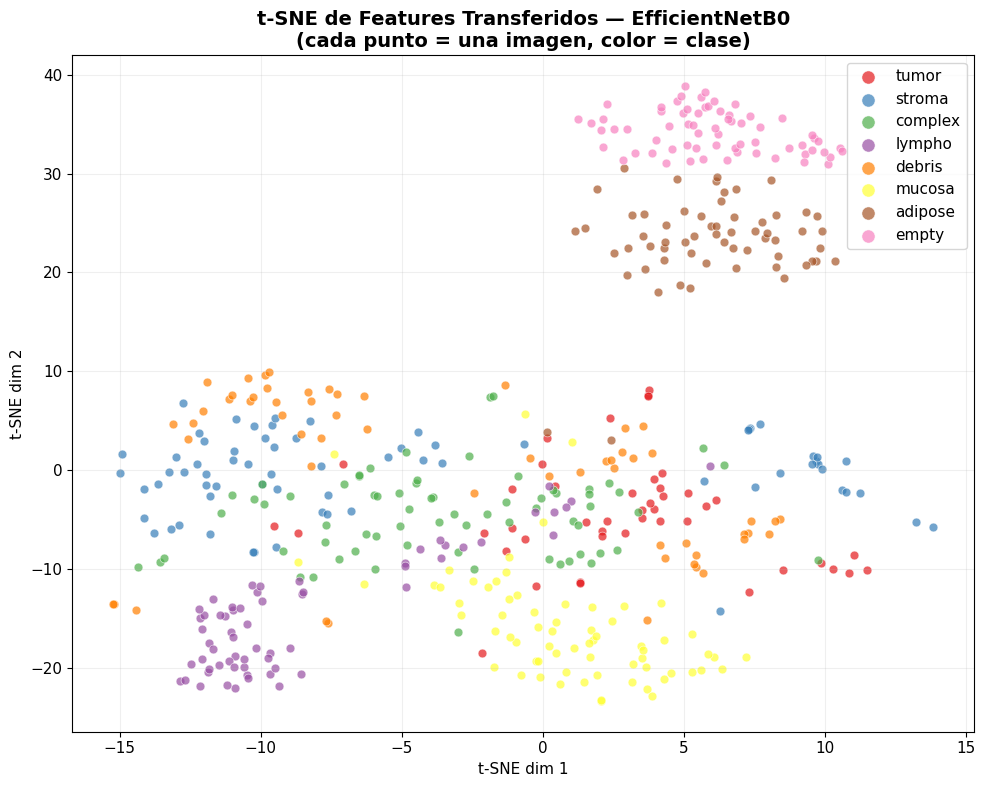


💡 Clases que forman clusters separados → el backbone distingue bien sus features
💡 Clases cuyos clusters se superponen → son visualmente similares (confusiones esperadas)


In [31]:
# Ejecutar t-SNE
print("🔄 Calculando t-SNE (esto toma ~30 segundos)...")
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30, max_iter=1000)
features_2d = tsne.fit_transform(features)

# Visualizar
fig, ax = plt.subplots(figsize=(10, 8))
scatter_colors = plt.cm.Set1(np.linspace(0, 0.8, NUM_CLASSES_2))

for class_idx in range(NUM_CLASSES_2):
    mask = labels == class_idx
    ax.scatter(features_2d[mask, 0], features_2d[mask, 1],
              c=[scatter_colors[class_idx]], label=CLASS_NAMES_2[class_idx],
              alpha=0.7, s=40, edgecolors='white', linewidths=0.5)

ax.set_title(f't-SNE de Features Transferidos — {best_name}\n'
            f'(cada punto = una imagen, color = clase)',
            fontsize=14, fontweight='bold')
ax.legend(fontsize=11, markerscale=1.5, loc='best')
ax.set_xlabel('t-SNE dim 1'); ax.set_ylabel('t-SNE dim 2')
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

print("\n💡 Clases que forman clusters separados → el backbone distingue bien sus features")
print("💡 Clases cuyos clusters se superponen → son visualmente similares (confusiones esperadas)")

### 3.5. Comparación t-SNE: Features aleatorios vs. Features transferidos

In [32]:
# Comparar: features de un backbone con pesos ALEATORIOS vs pesos de IMAGENET
# Esto demuestra el valor de Transfer Learning

# Backbone con pesos aleatorios (sin Transfer Learning)
base_random = tf.keras.applications.EfficientNetB0(
    weights=None,  # ¡Pesos aleatorios!
    include_top=False,
    input_shape=(224, 224, 3)
)

# Extraer features con pesos aleatorios
random_features = []
random_labels = []
count = 0
for imgs, lbls in val_generic:
    feats = base_random.predict(imgs, verbose=0)
    feats = tf.keras.layers.GlobalAveragePooling2D()(feats).numpy()
    random_features.append(feats)
    random_labels.append(np.argmax(lbls.numpy(), axis=1))
    count += imgs.shape[0]
    if count >= 500:
        break

random_features = np.concatenate(random_features)[:500]
random_labels_arr = np.concatenate(random_labels)[:500]

# t-SNE de features aleatorios
tsne_random = TSNE(n_components=2, random_state=SEED, perplexity=30)
random_2d = tsne_random.fit_transform(random_features)

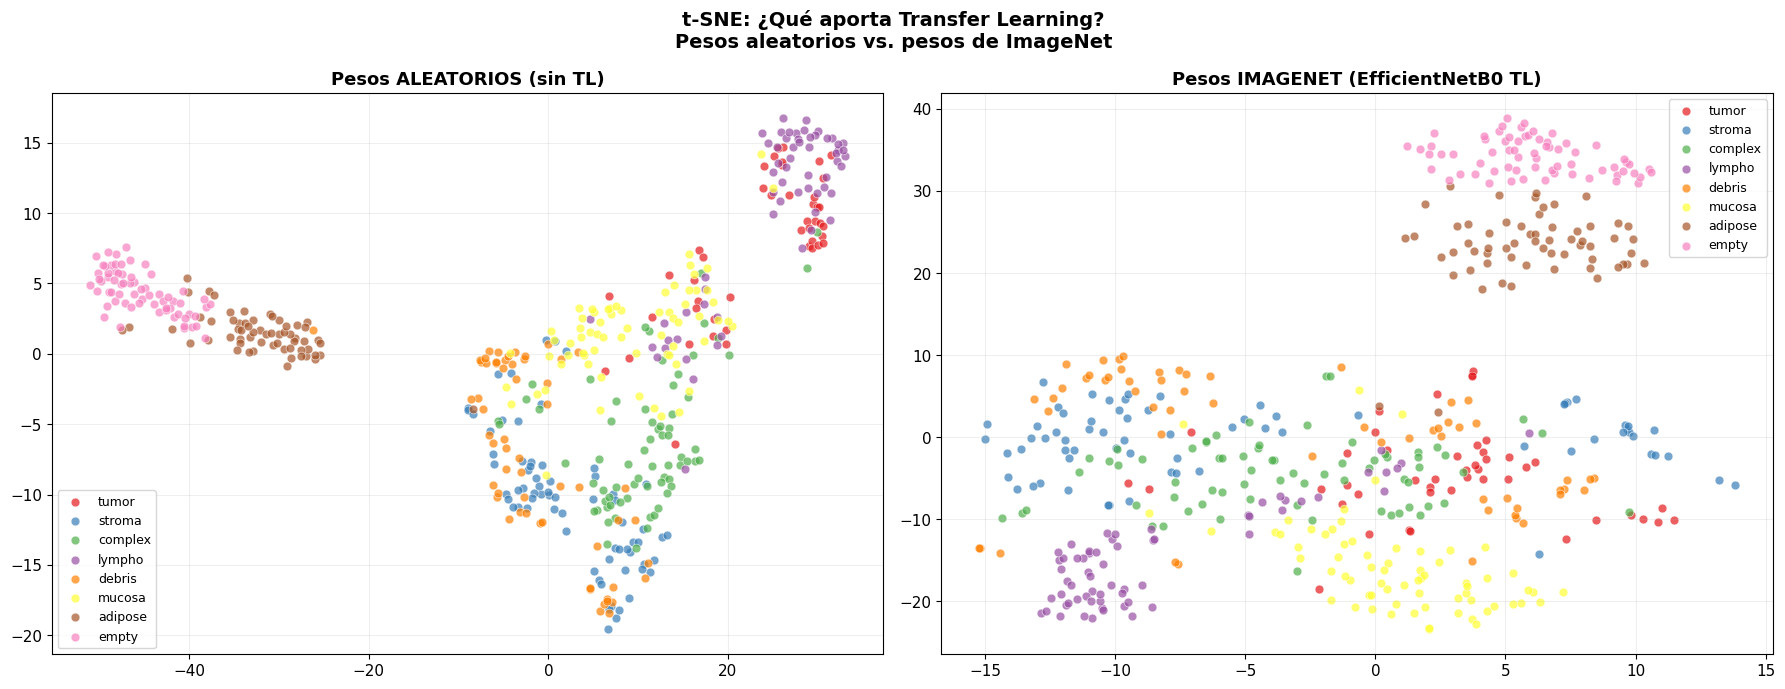

In [33]:
# Visualización lado a lado
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, data, lab, title_str in [
    (axes[0], random_2d, random_labels_arr, 'Pesos ALEATORIOS (sin TL)'),
    (axes[1], features_2d, labels, f'Pesos IMAGENET ({best_name} TL)')
]:
    for class_idx in range(NUM_CLASSES_2):
        mask = lab == class_idx
        ax.scatter(data[mask, 0], data[mask, 1],
                  c=[scatter_colors[class_idx]], label=CLASS_NAMES_2[class_idx],
                  alpha=0.7, s=40, edgecolors='white', linewidths=0.5)
    ax.set_title(title_str, fontsize=13, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.2)

plt.suptitle('t-SNE: ¿Qué aporta Transfer Learning?\n'
            'Pesos aleatorios vs. pesos de ImageNet',
            fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### ✅ Conclusión Ejemplo 3

**Hallazgos clave del benchmark:**
1. Backbone que lidera en accuracy: **EfficientNetB0** con 0.9360 (mejor época: 10), seguido de ResNet50 (0.9290), DenseNet121 (0.9030) y MobileNetV2 (0.8320). El resultado inesperado es MobileNetV2: es el que tiene el accuracy más bajo (0.8320), a más de 10 puntos de EfficientNetB0. Ver la advertencia sobre el preprocesamiento al final de esta sección.
2. Backbone más rápido de entrenar (tiempos): **MobileNetV2** con 79 s, pero con el menor accuracy; EfficientNetB0 fue el segundo más rápido (101 s) y el de mayor accuracy, seguido de ResNet50 (143 s) y DenseNet121, el más lento (205 s). Son tiempos totales de una sola corrida con `EarlyStopping`, y el notebook no imprime cuántas épocas ejecutó cada backbone, así que no equivalen a tiempo por época.
3. Backbone más pesado y su relación con la precisión: **ResNet50** (23,587,712 parámetros en el backbone, 267,400 entrenables) alcanzó 0.9290, por debajo de EfficientNetB0 (4,049,571 parámetros, 0.9360). En este benchmark más parámetros no se tradujeron en mejor accuracy.

**t-SNE:**
- ¿Los features de ImageNet separan las clases de histología **sin entrenamiento adicional**? Solo en parte. En el t-SNE de EfficientNetB0 (500 imágenes de validación), Adipose tissue y Background forman grupos compactos y bien separados, y Mucosal glands y Lympho forman grupos reconocibles, pero Tumour, Stroma, Complex y Debris se mezclan en la zona central. Eso es coherente con las confusiones Stroma/Complex del Ejemplo 2. Nota: el código extrae `model.layers[-5]`, que es la capa `BatchNormalization` del modelo ya entrenado, no el `GlobalAveragePooling2D` puro, por lo que no son exactamente los features ImageNet "sin tocar".
- Comparación con un backbone de pesos aleatorios: los pesos aleatorios también producen algo de estructura (Adipose y Background ya aparecen juntos y separados del resto, y Lympho/Tumour se agrupan a un lado), pero el resto de las clases forma una banda continua y solapada. Con pesos de ImageNet los grupos son más compactos y definidos (Mucosal glands, Lympho y la separación entre Adipose y Background), aunque la mejora es moderada, no una separación completa. t-SNE es una herramienta cualitativa y no mide accuracy.
- Qué nos dice esto sobre por qué (y hasta dónde) funciona Transfer Learning cuando el dominio es distinto al de ImageNet: los features de ImageNet ayudan (los modelos con backbone congelado llegan a 0.9360–0.9420 de accuracy en histología) y mejoran la organización respecto a pesos aleatorios, pero no resuelven todas las clases: las de textura parecida siguen solapadas. Esa es la limitación del dominio distinto, y la que Fine-Tuning intentaría reducir (no se evalúa aquí).

> ⚠️ **Precaución con el benchmark:** `benchmark_backbone` recibe `preprocess_fn=None` y nunca llama a `preprocess_input`, así que todos los backbones recibieron imágenes en [0, 255]. EfficientNetB0 incluye su normalización internamente (de ahí que su 0.9360 sea cercano al 0.9420 del Ejemplo 2), pero MobileNetV2, ResNet50 y DenseNet121 esperan otros rangos de entrada. Es probable que el bajo accuracy de MobileNetV2 (y en parte el de los demás) refleje esto y no solo la capacidad del backbone, por lo que el ranking debe leerse con cautela hasta volver a ejecutar con el preprocesamiento de cada modelo.

---
# 📋 Resumen de la Sesión 09-A

## Lo que aprendimos hoy

| Concepto | Descripción |
|----------|-------------|
| **Transfer Learning** | Reutilizar conocimiento de ImageNet para nuestro problema |
| **Feature Extraction** | Congelar backbone + entrenar solo clasificador nuevo |
| **`include_top=False`** | Remover las capas Dense originales de 1000 clases |
| **`trainable = False`** | Congelar todos los pesos del backbone |
| **`preprocess_input`** | Cada modelo tiene su propia normalización |
| **`training=False`** | Las capas BN usan estadísticos de ImageNet (estable) |
| **t-SNE** | Visualización de features de alta dimensión en 2D |

## Próximo paso: Sesión 09-B — Fine-Tuning

En Feature Extraction tratamos el backbone como caja negra. En **Fine-Tuning**, descongelaremos parte del backbone y lo re-entrenaremos con un learning rate bajo para **adaptar** los features a nuestro dominio → ¡mayor accuracy!

---
*IS056B — Ingeniería del Conocimiento | UNCP 2026-II | Msc. Jaime Huaytalla Pariona*